# Deblurring en GoPro: NAFNet + difusión residual

**Proyecto IA II**

**Integrantes:** Santiago Ardila, María Lucía Rodríguez, Juan Felipe Serrano

Pipeline completo sobre el **GoPro oficial** (Nah et al., CVPR 2017), variante `blur`, 1280×720:

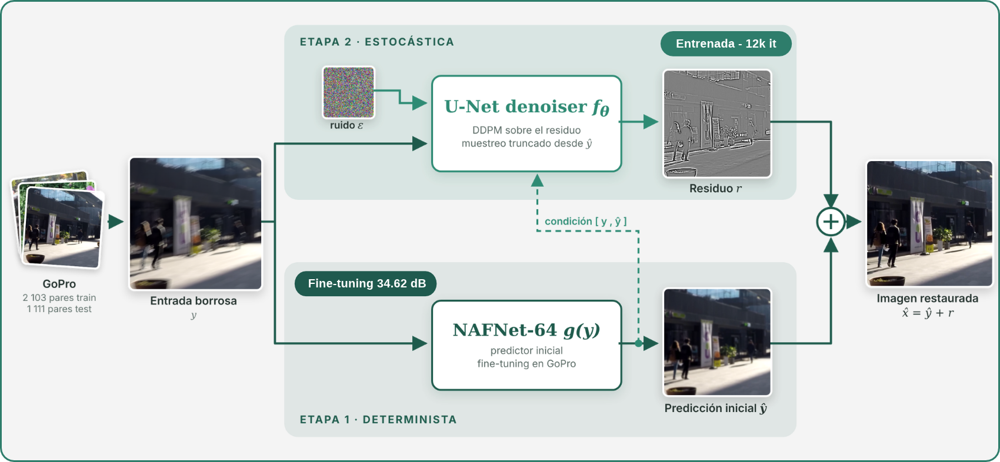

| Etapa | Qué hace | Dónde queda |
|---|---|---|
| 0. Datos | Copia el dataset de Drive al disco de Colab, separa **videos completos** para validación y arma una caché rápida | `split.json` en Drive |
| 1. NAFNet | Evalúa los pesos oficiales, hace el *fine-tuning* de control, elige el predictor y guarda sus predicciones ŷ | `nafnet/` y `preds_shards/` |
| 2. Difusión | Entrena la U-Net que genera el **residuo** r = x − ŷ (secuencial: NAFNet congelada). Variantes: bloques NAF y "difusión sola" | `difusion/<run>/` |
| 3. Evaluación | Ablaciones (100 imágenes) y tabla final (1111) con PSNR, SSIM y **LPIPS** | `eval/` |
| 4. Resultados cualitativos y gráficos | Percepción-distorsión, zoom, residuo, incertidumbre, animación del muestreo, espectro | `figuras/` |

## Configuración

In [ ]:
#@title Configuración (editar solo esta celda) { display-mode: "form" }
from google.colab import drive
drive.mount("/content/drive")

DATASET_PATH = "/content/drive/MyDrive/IA2_Deblurring/GOPRO_Large.zip"   #@param {type:"string"}
DRIVE_DIR    = "/content/drive/MyDrive/IA2_Deblurring"    #@param {type:"string"}

# ---- Etapa 1: NAFNet
RUN_FINETUNE = False   #@param {type:"boolean"}
FT_ITERS     = 20000   #@param {type:"integer"}

# ---- Etapa 2: difusión (se entrenan en este orden; cada una se puede retomar)
TRAIN_UNET = True      #@param {type:"boolean"}
TRAIN_NAF  = False     #@param {type:"boolean"}
TRAIN_SOLO = False     #@param {type:"boolean"}
DIFF_ITERS = 12000     #@param {type:"integer"}

# ---- Muestreo usado en la tabla final (ajústenlo según las ablaciones)
SAMPLE_STEPS = 10      #@param {type:"integer"}
SAMPLE_T0    = 0.5     #@param {type:"number"}

# ---- Evaluación
ABLATION_N = 30       #@param {type:"integer"}
FINAL_N    = 0         #@param {type:"integer"}
SAVE_PREDS_TO_DRIVE = True   #@param {type:"boolean"}

# ---- Opcional: cruce con los pesos ajustados en el GoPro de Kaggle (entrega 2)
RUN_CROSS = False      #@param {type:"boolean"}
KAGGLE_FT_WEIGHTS = "/content/drive/MyDrive/IA 2/Proyecto IA2/best.pth"   #@param {type:"string"}

import os
SRC, WORK = "/content/work/src", "/content/work"
DATA_DIR, CACHE, PREDS_ROOT = "/content/data", "/content/cache", "/content/preds"
SPLIT = f"{WORK}/split.json"
for d in (SRC, DATA_DIR, CACHE, PREDS_ROOT, DRIVE_DIR):
    os.makedirs(d, exist_ok=True)
os.environ["PYTHONUNBUFFERED"] = "1"
os.environ["TQDM_MININTERVAL"] = "10"
DIFF_RUNS = {"unet": dict(kind="unet", mode="residual", train=TRAIN_UNET),
             "naf":  dict(kind="naf",  mode="residual", train=TRAIN_NAF),
             "solo": dict(kind="unet", mode="solo",     train=TRAIN_SOLO)}
print("Todo lo persistente se guarda en:", DRIVE_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Todo lo persistente se guarda en: /content/drive/MyDrive/IA2_Deblurring


In [ ]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
!pip -q install lpips gdown
import torch
print("PyTorch", torch.__version__, "| GPU:", torch.cuda.is_available())
assert torch.cuda.is_available(), "Activa la GPU: Entorno de ejecución -> Cambiar tipo de entorno -> T4 GPU"

name, memory.total [MiB]
Tesla T4, 15360 MiB
PyTorch 2.14.1+cu130 | GPU: True


## Código
Estas celdas escriben los módulos en `/content/work/src`. No hace falta leerlos para usar el notebook
(pueden colapsar esta sección). La arquitectura de NAFNet es la de `nafnet_arch.py` del repositorio
(adaptada del repo oficial, licencia MIT).

In [ ]:
%%writefile /content/work/src/common.py
"""
Utilidades compartidas: dataset GoPro oficial, split por video, cache en disco,
metricas (PSNR, SSIM, LPIPS), inferencia por tiles y guardado seguro.
"""
import glob
import json
import os
import random
from concurrent.futures import ThreadPoolExecutor

import cv2
import numpy as np
import torch

cv2.setNumThreads(1)


# ----------------------------------------------------------------- dataset
def find_gopro_root(base):
    """Carpeta que contiene train/ y test/, con train/<SECUENCIA>/blur dentro."""
    for root, dirs, _ in os.walk(base):
        if "train" in dirs and "test" in dirs:
            tr = os.path.join(root, "train")
            if any(os.path.isdir(os.path.join(tr, d, "blur")) for d in os.listdir(tr)):
                return root
    raise FileNotFoundError(f"No encontre train/<secuencia>/blur dentro de {base}")


def list_split(root, split, variant="blur", seqs=None):
    """Lista de dicts {seq, name, blur, sharp} en orden (secuencia, frame)."""
    items = []
    sdir = os.path.join(root, split)
    for seq in sorted(os.listdir(sdir)):
        if seqs is not None and seq not in seqs:
            continue
        bdir, shdir = os.path.join(sdir, seq, variant), os.path.join(sdir, seq, "sharp")
        if not os.path.isdir(bdir):
            continue
        for b in sorted(glob.glob(os.path.join(bdir, "*.png"))):
            s = os.path.join(shdir, os.path.basename(b))
            if os.path.isfile(s):
                items.append({"seq": seq, "name": os.path.basename(b), "blur": b, "sharp": s})
    return items


def video_id(seq):
    """GOPR0374_11_02 -> GOPR0374 (varias secuencias salen del mismo video)."""
    return seq.split("_")[0]


def make_split(root, val_frac=0.10, seed=0):
    """Separa videos COMPLETOS del train como validacion (~val_frac de los frames)."""
    items = list_split(root, "train")
    count, seqs_of = {}, {}
    for it in items:
        v = video_id(it["seq"])
        count[v] = count.get(v, 0) + 1
        seqs_of.setdefault(v, set()).add(it["seq"])
    order = sorted(count)
    random.Random(seed).shuffle(order)
    target, val_v, n = val_frac * len(items), [], 0
    for v in order[:-1]:
        if n >= target:
            break
        if n + count[v] > 2 * target:   # evita que un video enorme se lleve todo
            continue
        val_v.append(v)
        n += count[v]
    val = sorted(s for v in val_v for s in seqs_of[v])
    train = sorted(s for v in count if v not in val_v for s in seqs_of[v])
    return {"val_videos": sorted(val_v), "train": train, "val": val,
            "n_train": len(items) - n, "n_val": n, "seed": seed}


def split_items(root, split_json, part, variant="blur"):
    """part in {'train','val','test'} -> lista de items."""
    if part == "test":
        return list_split(root, "test", variant)
    with open(split_json) as f:
        sp = json.load(f)
    return list_split(root, "train", variant, set(sp[part]))


def evenly(items, n):
    if not n or n >= len(items):
        return list(items)
    idx = np.linspace(0, len(items) - 1, n).round().astype(int)
    return [items[i] for i in idx]


def pred_path(preds_dir, part, item):
    return os.path.join(preds_dir, part, item["seq"], item["name"])


# ------------------------------------------------------------- imagenes
def read_u8(path):
    img = cv2.imread(path, cv2.IMREAD_COLOR)
    if img is None:
        raise IOError(f"No se pudo leer {path}")
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def write_u8(path, img):
    os.makedirs(os.path.dirname(path), exist_ok=True)
    tmp = path + ".tmp.png"
    cv2.imwrite(tmp, cv2.cvtColor(img, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_PNG_COMPRESSION, 3])
    os.replace(tmp, path)


def to_u8(x01):
    return np.round(np.clip(x01, 0, 1) * 255).astype(np.uint8)


def u8_to_t(img, device, signed=True):
    """uint8 HxWx3 -> tensor 1x3xHxW en [-1,1] (signed) o [0,1]."""
    t = torch.from_numpy(np.ascontiguousarray(img)).permute(2, 0, 1)[None].float().div(255).to(device)
    return t * 2 - 1 if signed else t


def t_to_u8(t, signed=True):
    t = t.detach().float()[0]
    t = (t + 1) / 2 if signed else t
    return to_u8(t.clamp(0, 1).permute(1, 2, 0).cpu().numpy())


# ------------------------------------------------------------- metricas
def psnr_u8(a, b):
    mse = np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2)
    return float("inf") if mse == 0 else float(10 * np.log10(255.0 ** 2 / mse))


def ssim_u8(a, b):
    from skimage.metrics import structural_similarity
    return float(structural_similarity(a, b, channel_axis=2, data_range=255))


class LPIPSMetric:
    """LPIPS (AlexNet). Menor = mas parecido perceptualmente. Entradas uint8 HxWx3."""

    def __init__(self, device):
        import lpips
        self.device = device
        self.fn = lpips.LPIPS(net="alex", verbose=False).to(device).eval()

    @torch.no_grad()
    def __call__(self, a, b):
        return float(self.fn(u8_to_t(a, self.device), u8_to_t(b, self.device)))


def try_lpips(device, enabled=True):
    if not enabled:
        return None
    try:
        return LPIPSMetric(device)
    except Exception as e:  # sin internet para bajar AlexNet, etc.
        print(f"[!] LPIPS no disponible ({e}); se omite")
        return None


# ---------------------------------------------------------------- tiles
def _starts(size, tile, stride):
    if size <= tile:
        return [0]
    return sorted(set(list(range(0, size - tile, stride)) + [size - tile]))


def _ramp(n, overlap, lo, hi, device):
    w = torch.ones(n, device=device)
    if overlap <= 0:
        return w
    margin = overlap // 4
    r = torch.cat([torch.zeros(margin, device=device),
                   torch.linspace(0, 1, overlap - margin + 2, device=device)[1:-1]])
    if lo:
        w[:overlap] = r
    if hi:
        w[-overlap:] = torch.minimum(w[-overlap:], r.flip(0))
    return w


@torch.no_grad()
def tiled_forward(fn, inputs, tile=256, overlap=32, max_batch=8):
    """
    Aplica fn(*inputs) por tiles solapados (inputs con batch 1) y mezcla con pesos.
    Los tiles se procesan en lotes de max_batch para aprovechar la GPU.
    fn debe aceptar un batch de tiles y devolver la misma H, W.
    """
    H, W = inputs[0].shape[-2:]
    if tile is None or (H <= tile and W <= tile):
        return fn(*inputs).float()
    th, tw = min(tile, H), min(tile, W)
    coords = [(y, x) for y in _starts(H, tile, tile - overlap) for x in _starts(W, tile, tile - overlap)]
    out = wsum = None
    for i in range(0, len(coords), max_batch):
        chunk = coords[i:i + max_batch]
        crops = [torch.cat([t[..., y:y + th, x:x + tw] for y, x in chunk], 0) for t in inputs]
        o = fn(*crops).float()
        if out is None:
            out = torch.zeros((1, o.shape[1], H, W), device=o.device)
            wsum = torch.zeros((1, 1, H, W), device=o.device)
        for k, (y, x) in enumerate(chunk):
            w = (_ramp(th, overlap, y > 0, y + th < H, o.device)[:, None]
                 * _ramp(tw, overlap, x > 0, x + tw < W, o.device)[None, :])
            out[..., y:y + th, x:x + tw] += o[k:k + 1] * w
            wsum[..., y:y + th, x:x + tw] += w
    return out / wsum.clamp_min(1e-8)


# --------------------------------------------------------- cache en disco
def build_cache(paths, out_path, workers=4):
    """
    Guarda las imagenes (todas del mismo tamano) en un np.memmap uint8 (N,H,W,3).
    Leer recortes de ahi es mucho mas rapido que decodificar PNG en cada paso.
    """
    meta_path = out_path + ".json"
    if os.path.isfile(out_path) and os.path.isfile(meta_path):
        with open(meta_path) as f:
            meta = json.load(f)
        if meta["n"] == len(paths):
            return open_cache(out_path)
    h, w = read_u8(paths[0]).shape[:2]
    os.makedirs(os.path.dirname(out_path) or ".", exist_ok=True)
    tmp = out_path + ".tmp"
    mm = np.lib.format.open_memmap(tmp, mode="w+", dtype=np.uint8, shape=(len(paths), h, w, 3))
    with ThreadPoolExecutor(workers) as ex:
        for i, img in enumerate(ex.map(read_u8, paths)):
            mm[i] = img
    mm.flush()
    del mm
    os.replace(tmp, out_path)
    with open(meta_path, "w") as f:
        json.dump({"n": len(paths), "h": h, "w": w}, f)
    return open_cache(out_path)


def open_cache(path):
    return np.load(path, mmap_mode="r")


def _tile_size(n, target=256, minimum=128):
    for t in range(target, minimum - 1, -1):
        if n % t == 0:
            return t
    return n


def build_tile_cache(triples, out_path, workers=4):
    """
    Cache para entrenar la difusion: por imagen, borrosa+nitida+prediccion
    intercaladas (9 canales) y cortadas en mosaicos contiguos (p. ej. 3x5 de 240x256).
    Asi cada recorte se lee de UNA zona contigua del disco, en vez de cientos de filas
    dispersas en tres archivos (lo que hacia lento el entrenamiento en Colab).
    """
    meta_path = out_path + ".json"
    if os.path.isfile(out_path) and os.path.isfile(meta_path):
        with open(meta_path) as f:
            if json.load(f)["n"] == len(triples):
                return open_cache(out_path)
    h, w = read_u8(triples[0][0]).shape[:2]
    th, tw = _tile_size(h), _tile_size(w)
    ny, nx = h // th, w // tw
    os.makedirs(os.path.dirname(out_path) or ".", exist_ok=True)
    tmp = out_path + ".tmp"
    mm = np.lib.format.open_memmap(tmp, mode="w+", dtype=np.uint8, shape=(len(triples), ny, nx, th, tw, 9))

    def load(tr):
        a = np.concatenate([read_u8(p) for p in tr], axis=2)[:ny * th, :nx * tw]
        return a.reshape(ny, th, nx, tw, 9).transpose(0, 2, 1, 3, 4)

    with ThreadPoolExecutor(workers) as ex:
        for i, a in enumerate(ex.map(load, triples)):
            mm[i] = a
    mm.flush()
    del mm
    os.replace(tmp, out_path)
    with open(meta_path, "w") as f:
        json.dump({"n": len(triples), "h": h, "w": w, "tile": [th, tw]}, f)
    return open_cache(out_path)


def random_tile_crop(arr, idx, patch, rng):
    """Recorte aleatorio (patch x patch x 9) dentro de un mosaico, con flips/rotacion."""
    _, ny, nx, th, tw, _ = arr.shape
    ty, tx = rng.randrange(ny), rng.randrange(nx)
    y, x = rng.randint(0, th - patch), rng.randint(0, tw - patch)
    c = np.asarray(arr[idx, ty, tx, y:y + patch, x:x + patch])
    if rng.random() < 0.5:
        c = c[:, ::-1]
    if rng.random() < 0.5:
        c = c[::-1]
    k = rng.randint(0, 3)
    if k:
        c = np.rot90(c, k)
    t = torch.from_numpy(np.ascontiguousarray(c)).permute(2, 0, 1)
    return t[0:3], t[3:6], t[6:9]


def random_crops(arrays, idx, patch, rng):
    """Mismo recorte + flips/rotacion para todos los arrays (memmaps N,H,W,3)."""
    H, W = arrays[0].shape[1:3]
    y, x = rng.randint(0, H - patch), rng.randint(0, W - patch)
    crops = [np.asarray(a[idx, y:y + patch, x:x + patch]) for a in arrays]
    if rng.random() < 0.5:
        crops = [c[:, ::-1] for c in crops]
    if rng.random() < 0.5:
        crops = [c[::-1] for c in crops]
    k = rng.randint(0, 3)
    if k:
        crops = [np.rot90(c, k) for c in crops]
    return [torch.from_numpy(np.ascontiguousarray(c)).permute(2, 0, 1) for c in crops]


# ------------------------------------------------------- guardado seguro
def save_atomic(obj, path):
    """torch.save a un temporal y luego rename: si se corta, no queda un archivo roto."""
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    tmp = path + ".tmp"
    torch.save(obj, tmp)
    os.replace(tmp, path)


def save_json(obj, path):
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    tmp = path + ".tmp"
    with open(tmp, "w") as f:
        json.dump(obj, f, indent=2)
    os.replace(tmp, path)


def load_json(path, default=None):
    if not os.path.isfile(path):
        return default
    with open(path) as f:
        return json.load(f)


def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def worker_init(wid):
    s = (torch.initial_seed() + wid) % 2 ** 32
    random.seed(s)
    np.random.seed(s)

Writing /content/work/src/common.py


In [ ]:
%%writefile /content/work/src/nafnet_arch.py
"""
NAFNet autocontenido (sin dependencia de BasicSR).

Adaptado del repositorio oficial:
    https://github.com/megvii-research/NAFNet  (MIT License, (c) 2022 megvii-model)
    Chen et al., "Simple Baselines for Image Restoration", ECCV 2022.

Cambios respecto al original:
  * LayerNorm2d y el pooling local se calculan siempre en fp32, para que la
    inferencia con autocast (fp16) no pierda precision (cumsum en fp16 desborda).
  * El TLC (Test-time Local Converter, Chu et al. 2021) se implementa de forma
    explicita: cada pooling global de la atencion de canal se reemplaza por un
    pooling local cuyo tamano equivale a 1.5x el parche de entrenamiento (256),
    igual que la configuracion oficial de test `NAFNetLocal`.
"""
import torch
import torch.nn as nn
import torch.nn.functional as F


# --------------------------------------------------------------------------
# Bloques basicos
# --------------------------------------------------------------------------
class LayerNorm2d(nn.Module):
    """LayerNorm sobre el eje de canales, calculado en fp32."""

    def __init__(self, channels, eps=1e-6):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(channels))
        self.bias = nn.Parameter(torch.zeros(channels))
        self.eps = eps

    def forward(self, x):
        dtype = x.dtype
        x = x.float()
        mu = x.mean(1, keepdim=True)
        var = (x - mu).pow(2).mean(1, keepdim=True)
        y = (x - mu) / (var + self.eps).sqrt()
        y = self.weight.float().view(1, -1, 1, 1) * y + self.bias.float().view(1, -1, 1, 1)
        return y.to(dtype)


class SimpleGate(nn.Module):
    def forward(self, x):
        x1, x2 = x.chunk(2, dim=1)
        return x1 * x2


class LocalAvgPool2d(nn.Module):
    """
    Pooling local del TLC. `kernel_size` esta en pixeles del mapa de features
    y se fija una sola vez con `NAFNet.enable_tlc()`.
    Si el kernel cubre todo el mapa, equivale al pooling global original.
    """

    def __init__(self):
        super().__init__()
        self.kernel_size = None  # (kh, kw), se asigna en enable_tlc

    def forward(self, x):
        if self.kernel_size is None:
            return F.adaptive_avg_pool2d(x, 1)
        n, c, h, w = x.shape
        k1, k2 = min(h, self.kernel_size[0]), min(w, self.kernel_size[1])
        if k1 >= h and k2 >= w:
            return F.adaptive_avg_pool2d(x, 1)

        dtype = x.dtype
        s = x.float().cumsum(dim=-1).cumsum_(dim=-2)
        s = F.pad(s, (1, 0, 1, 0))
        out = (s[:, :, k1:, k2:] + s[:, :, :-k1, :-k2]
               - s[:, :, :-k1, k2:] - s[:, :, k1:, :-k2]) / (k1 * k2)
        _h, _w = out.shape[2:]
        pad = ((w - _w) // 2, (w - _w + 1) // 2, (h - _h) // 2, (h - _h + 1) // 2)
        out = F.pad(out, pad, mode='replicate')
        return out.to(dtype)


class NAFBlock(nn.Module):
    def __init__(self, c, dw_expand=2, ffn_expand=2):
        super().__init__()
        dw = c * dw_expand
        self.conv1 = nn.Conv2d(c, dw, 1)
        self.conv2 = nn.Conv2d(dw, dw, 3, padding=1, groups=dw)
        self.conv3 = nn.Conv2d(dw // 2, c, 1)
        # Simplified Channel Attention (los nombres coinciden con los pesos oficiales)
        self.sca = nn.Sequential(LocalAvgPool2d(), nn.Conv2d(dw // 2, dw // 2, 1))
        self.sg = SimpleGate()

        ffn = ffn_expand * c
        self.conv4 = nn.Conv2d(c, ffn, 1)
        self.conv5 = nn.Conv2d(ffn // 2, c, 1)

        self.norm1 = LayerNorm2d(c)
        self.norm2 = LayerNorm2d(c)
        self.beta = nn.Parameter(torch.zeros((1, c, 1, 1)))
        self.gamma = nn.Parameter(torch.zeros((1, c, 1, 1)))

    def forward(self, inp):
        x = self.norm1(inp)
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.sg(x)
        x = x * self.sca(x)
        x = self.conv3(x)
        y = inp + x * self.beta

        x = self.conv4(self.norm2(y))
        x = self.sg(x)
        x = self.conv5(x)
        return y + x * self.gamma


# --------------------------------------------------------------------------
# Red completa
# --------------------------------------------------------------------------
class NAFNet(nn.Module):
    def __init__(self, img_channel=3, width=64, middle_blk_num=1,
                 enc_blk_nums=(1, 1, 1, 28), dec_blk_nums=(1, 1, 1, 1)):
        super().__init__()
        self.intro = nn.Conv2d(img_channel, width, 3, padding=1)
        self.ending = nn.Conv2d(width, img_channel, 3, padding=1)

        self.encoders = nn.ModuleList()
        self.decoders = nn.ModuleList()
        self.ups = nn.ModuleList()
        self.downs = nn.ModuleList()

        chan = width
        for num in enc_blk_nums:
            self.encoders.append(nn.Sequential(*[NAFBlock(chan) for _ in range(num)]))
            self.downs.append(nn.Conv2d(chan, 2 * chan, 2, 2))
            chan *= 2

        self.middle_blks = nn.Sequential(*[NAFBlock(chan) for _ in range(middle_blk_num)])

        for num in dec_blk_nums:
            self.ups.append(nn.Sequential(nn.Conv2d(chan, chan * 2, 1, bias=False),
                                          nn.PixelShuffle(2)))
            chan //= 2
            self.decoders.append(nn.Sequential(*[NAFBlock(chan) for _ in range(num)]))

        self.padder_size = 2 ** len(self.encoders)

    # ---------------- TLC ----------------
    def _set_pool_kernels(self, module, kernel):
        for m in module.modules():
            if isinstance(m, LocalAvgPool2d):
                m.kernel_size = (kernel, kernel)

    def enable_tlc(self, train_size=256, ratio=1.5):
        """
        Replica `NAFNetLocal` oficial: base_size = 1.5 * train_size.
        En cada nivel (resolucion 1/2^i) el kernel es base_size / 2^i.
        """
        base = int(train_size * ratio)
        for i, enc in enumerate(self.encoders):
            self._set_pool_kernels(enc, base // (2 ** i))
        self._set_pool_kernels(self.middle_blks, base // (2 ** len(self.encoders)))
        n = len(self.decoders)
        for j, dec in enumerate(self.decoders):
            self._set_pool_kernels(dec, base // (2 ** (n - 1 - j)))
        return self

    # ---------------- forward ----------------
    def forward(self, inp):
        _, _, H, W = inp.shape
        inp = self._pad(inp)

        x = self.intro(inp)
        encs = []
        for encoder, down in zip(self.encoders, self.downs):
            x = encoder(x)
            encs.append(x)
            x = down(x)

        x = self.middle_blks(x)

        for decoder, up, skip in zip(self.decoders, self.ups, encs[::-1]):
            x = up(x)
            x = x + skip
            x = decoder(x)

        # Residual global en fp32 para no perder precision en la salida
        x = self.ending(x).float() + inp.float()
        return x[:, :, :H, :W]

    def _pad(self, x):
        _, _, h, w = x.shape
        ph = (self.padder_size - h % self.padder_size) % self.padder_size
        pw = (self.padder_size - w % self.padder_size) % self.padder_size
        return F.pad(x, (0, pw, 0, ph))


# --------------------------------------------------------------------------
# Utilidades
# --------------------------------------------------------------------------
def enable_grad_checkpointing(net):
    """
    Envuelve cada NAFBlock con torch.utils.checkpoint: en entrenamiento no guarda
    sus activaciones y las recalcula en el backward (menos VRAM, ~30% mas lento).
    """
    from torch.utils.checkpoint import checkpoint

    for m in net.modules():
        if isinstance(m, NAFBlock) and not hasattr(m, "_orig_forward"):
            m._orig_forward = m.forward

            def fwd(x, _m=m):
                if _m.training and torch.is_grad_enabled():
                    return checkpoint(_m._orig_forward, x, use_reentrant=False)
                return _m._orig_forward(x)

            m.forward = fwd
    return net


NAFNET_CONFIGS = {
    # nombre : (width, enc_blk_nums, middle_blk_num, dec_blk_nums)
    "NAFNet-GoPro-width64": (64, (1, 1, 1, 28), 1, (1, 1, 1, 1)),
    "NAFNet-GoPro-width32": (32, (1, 1, 1, 28), 1, (1, 1, 1, 1)),
    # Solo para pruebas rapidas del pipeline (no tiene pesos oficiales)
    "NAFNet-tiny": (8, (1, 1), 1, (1, 1)),
}


def build_nafnet(name="NAFNet-GoPro-width64", weights=None, tlc=True, device="cpu"):
    width, enc, mid, dec = NAFNET_CONFIGS[name]
    net = NAFNet(width=width, enc_blk_nums=enc, middle_blk_num=mid, dec_blk_nums=dec)
    if weights is not None:
        ckpt = torch.load(weights, map_location="cpu", weights_only=False)
        state = ckpt.get("params", ckpt) if isinstance(ckpt, dict) else ckpt
        state = {k.replace("module.", "", 1): v for k, v in state.items()}
        net.load_state_dict(state, strict=True)
    if tlc:
        net.enable_tlc()
    return net.to(device).eval()

Writing /content/work/src/nafnet_arch.py


In [ ]:
%%writefile /content/work/src/prepare.py
"""
Preparacion de datos:
  split        crea (o reutiliza) split.json con videos completos para validacion
  cache-data   guarda train blur/sharp en np.memmap (lectura rapida de recortes)
  cache-preds  guarda las predicciones de NAFNet de train en np.memmap
  cache-tiles  borrosa + nitida + prediccion de train en mosaicos contiguos (difusion)
"""
import argparse
import os
import shutil

from common import build_cache, build_tile_cache, load_json, make_split, pred_path, save_json, split_items


def main(argv=None):
    ap = argparse.ArgumentParser()
    ap.add_argument("cmd", choices=["split", "cache-data", "cache-preds", "cache-tiles"])
    ap.add_argument("--root", required=True)
    ap.add_argument("--split_json", required=True, help="ruta local del split")
    ap.add_argument("--drive_split", default=None, help="copia persistente en Drive")
    ap.add_argument("--cache_dir", default="/content/cache")
    ap.add_argument("--preds_dir", default=None)
    ap.add_argument("--val_frac", type=float, default=0.10)
    ap.add_argument("--workers", type=int, default=4)
    args = ap.parse_args(argv)

    if args.cmd == "split":
        if args.drive_split and os.path.isfile(args.drive_split):
            os.makedirs(os.path.dirname(args.split_json) or ".", exist_ok=True)
            shutil.copy(args.drive_split, args.split_json)
            sp = load_json(args.split_json)
            print("Split reutilizado desde Drive")
        else:
            sp = make_split(args.root, args.val_frac)
            save_json(sp, args.split_json)
            if args.drive_split:
                save_json(sp, args.drive_split)
            print("Split nuevo guardado")
        print(f"  train: {sp['n_train']} pares ({len(sp['train'])} secuencias)")
        print(f"  val:   {sp['n_val']} pares ({len(sp['val'])} secuencias, videos {sp['val_videos']})")
        return

    items = split_items(args.root, args.split_json, "train")
    if args.cmd == "cache-data":
        for key in ("blur", "sharp"):
            mm = build_cache([it[key] for it in items], os.path.join(args.cache_dir, f"train_{key}.npy"),
                             args.workers)
            print(f"cache train_{key}: {mm.shape}")
    elif args.cmd == "cache-tiles":
        triples = [(it["blur"], it["sharp"], pred_path(args.preds_dir, "train", it)) for it in items]
        missing = [t[2] for t in triples if not os.path.isfile(t[2])]
        if missing:
            raise SystemExit(f"Faltan {len(missing)} predicciones de train (corre la prediccion primero)")
        mm = build_tile_cache(triples, os.path.join(args.cache_dir, "train_tiles.npy"), args.workers)
        print(f"cache train_tiles: {mm.shape}")
    else:
        paths = [pred_path(args.preds_dir, "train", it) for it in items]
        missing = [p for p in paths if not os.path.isfile(p)]
        if missing:
            raise SystemExit(f"Faltan {len(missing)} predicciones de train (corre la prediccion primero)")
        mm = build_cache(paths, os.path.join(args.cache_dir, "train_pred.npy"), args.workers)
        print(f"cache train_pred: {mm.shape}")


if __name__ == "__main__":
    main()

Writing /content/work/src/prepare.py


In [ ]:
%%writefile /content/work/src/finetune.py
"""
Etapa 1 (opcional, control): fine-tuning de NAFNet-64 desde los pesos oficiales,
con la misma receta de la entrega 2 (PSNR loss, parches 256, LR 3e-5, fp16,
gradient checkpointing), entrenando SIN los videos de validacion.

Reanudable: guarda last.pt (pesos + optimizador) en Drive cada --save_every
iteraciones con escritura atomica; al relanzar continua desde ahi.
"""
import argparse
import csv
import math
import os
import random
import time

import numpy as np
import torch
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

from common import (evenly, open_cache, psnr_u8, random_crops, read_u8, save_atomic,
                    save_json, seed_all, split_items, t_to_u8, tiled_forward, u8_to_t,
                    worker_init)
from nafnet_arch import build_nafnet, enable_grad_checkpointing


class MemmapPatches(Dataset):
    def __init__(self, blur_path, sharp_path, patch):
        self.paths, self.patch = (blur_path, sharp_path), patch
        self.arrs = None
        self.n = open_cache(blur_path).shape[0]

    def __len__(self):
        return 10 ** 9

    def __getitem__(self, _):
        if self.arrs is None:
            self.arrs = [open_cache(p) for p in self.paths]
        b, s = random_crops(self.arrs, random.randrange(self.n), self.patch, random)
        return b.float() / 255, s.float() / 255


def psnr_loss(pred, target):
    mse = ((pred.float() - target.float()) ** 2).mean(dim=(1, 2, 3))
    return (10.0 / math.log(10.0)) * torch.log(mse + 1e-8).mean()


@torch.no_grad()
def nafnet_predict(net, blur_u8, device, tile=None):
    x = u8_to_t(blur_u8, device, signed=False)
    with torch.autocast(device.type, dtype=torch.float16, enabled=device.type == "cuda"):
        y = tiled_forward(net, [x], tile, 64) if tile else net(x).float()
    return t_to_u8(y.clamp(0, 1), signed=False)


@torch.no_grad()
def validate(net, items, device, tile):
    net.eval()
    v = [psnr_u8(nafnet_predict(net, read_u8(it["blur"]), device, tile), read_u8(it["sharp"]))
         for it in items]
    net.train()
    return float(np.mean(v))


def main(argv=None):
    ap = argparse.ArgumentParser()
    ap.add_argument("--root", required=True)
    ap.add_argument("--split_json", required=True)
    ap.add_argument("--cache_dir", required=True)
    ap.add_argument("--out_dir", required=True)
    ap.add_argument("--weights", required=True, help="pesos oficiales de partida")
    ap.add_argument("--model", default="NAFNet-GoPro-width64")
    ap.add_argument("--iters", type=int, default=20000)
    ap.add_argument("--batch", type=int, default=2)
    ap.add_argument("--patch", type=int, default=256)
    ap.add_argument("--lr", type=float, default=3e-5)
    ap.add_argument("--warmup", type=int, default=500)
    ap.add_argument("--val_images", type=int, default=40)
    ap.add_argument("--val_every", type=int, default=2000)
    ap.add_argument("--save_every", type=int, default=2000)
    ap.add_argument("--workers", type=int, default=2)
    ap.add_argument("--tile", type=int, default=0, help="0 = imagen completa")
    ap.add_argument("--seed", type=int, default=0)
    args = ap.parse_args(argv)

    seed_all(args.seed)
    os.makedirs(args.out_dir, exist_ok=True)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    amp = device.type == "cuda"
    tile = args.tile or None

    last_path = os.path.join(args.out_dir, "last.pt")
    best_path = os.path.join(args.out_dir, "best.pth")
    log_path = os.path.join(args.out_dir, "log.csv")
    done_path = os.path.join(args.out_dir, "DONE.json")
    if os.path.isfile(done_path):
        print("Fine-tuning ya terminado:", open(done_path).read())
        return

    val_items = evenly(split_items(args.root, args.split_json, "val"), args.val_images)
    loader = DataLoader(
        MemmapPatches(os.path.join(args.cache_dir, "train_blur.npy"),
                      os.path.join(args.cache_dir, "train_sharp.npy"), args.patch),
        batch_size=args.batch, num_workers=args.workers, pin_memory=amp,
        worker_init_fn=worker_init, persistent_workers=args.workers > 0)
    it_loader = iter(loader)

    net = build_nafnet(args.model, args.weights, tlc=True, device=device)
    enable_grad_checkpointing(net)
    net.train()
    opt = torch.optim.AdamW(net.parameters(), lr=args.lr, betas=(0.9, 0.9), weight_decay=0.0)
    scaler = torch.amp.GradScaler("cuda", enabled=amp)

    def lr_at(it):
        if it < args.warmup:
            return args.lr * (it + 1) / args.warmup
        t = (it - args.warmup) / max(1, args.iters - args.warmup)
        return 1e-7 + 0.5 * (args.lr - 1e-7) * (1 + math.cos(math.pi * t))

    start, best = 0, -1.0
    if os.path.isfile(last_path):
        ck = torch.load(last_path, map_location=device, weights_only=False)
        net.load_state_dict(ck["params"])
        opt.load_state_dict(ck["opt"])
        scaler.load_state_dict(ck["scaler"])
        start, best = ck["iter"], ck["best"]
        print(f"Reanudando fine-tuning desde la iteracion {start} (mejor val {best:.2f} dB)")
    else:
        best = validate(net, val_items, device, tile)
        print(f"Validacion con pesos oficiales (iter 0): {best:.2f} dB")
        with open(log_path, "w", newline="") as f:
            csv.writer(f).writerows([["iter", "val_psnr", "lr", "loss"], [0, best, 0, ""]])
        save_atomic({"params": net.state_dict()}, best_path)

    def save_last(it):
        save_atomic({"params": net.state_dict(), "opt": opt.state_dict(),
                     "scaler": scaler.state_dict(), "iter": it, "best": best}, last_path)

    t0, run = time.time(), []
    pbar = tqdm(range(start, args.iters), initial=start, total=args.iters, desc="fine-tuning")
    for it in pbar:
        for g in opt.param_groups:
            g["lr"] = lr_at(it)
        blur, sharp = (t.to(device, non_blocking=True) for t in next(it_loader))
        with torch.autocast(device.type, dtype=torch.float16, enabled=amp):
            pred = net(blur)
        loss = psnr_loss(pred, sharp)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(net.parameters(), 0.01)
        scaler.step(opt)
        scaler.update()
        run.append(loss.item())
        if (it + 1) % 50 == 0:
            pbar.set_postfix(loss=f"{np.mean(run[-50:]):.3f}", lr=f"{lr_at(it):.1e}")

        last_iter = it + 1 == args.iters
        if (it + 1) % args.val_every == 0 or last_iter:
            v = validate(net, val_items, device, tile)
            tag = ""
            if v > best:
                best = v
                save_atomic({"params": net.state_dict()}, best_path)
                tag = "  <- mejor"
            tqdm.write(f"[iter {it + 1}] val PSNR = {v:.2f} dB{tag}")
            with open(log_path, "a", newline="") as f:
                csv.writer(f).writerow([it + 1, v, lr_at(it), np.mean(run[-500:])])
        if (it + 1) % args.save_every == 0 or last_iter:
            save_last(it + 1)

    save_json({"iters": args.iters, "best_val_psnr": best,
               "hours_last_session": (time.time() - t0) / 3600}, done_path)
    print(f"Listo. Mejor val PSNR: {best:.2f} dB -> {best_path}")


if __name__ == "__main__":
    main()

Writing /content/work/src/finetune.py


In [ ]:
%%writefile /content/work/src/predict.py
"""
Corre una NAFNet sobre un split, guarda sus predicciones (PNG de 8 bits, en el
disco local) y sus metricas por imagen (CSV en Drive).

Reanudable: las filas ya escritas en el CSV no se recalculan; con --need_preds
tambien se regeneran los PNG que falten (p. ej. despues de reiniciar Colab).
"""
import argparse
import csv
import glob
import os
import shutil
import tarfile
import time

import numpy as np
import torch
from tqdm.auto import tqdm

from common import (evenly, load_json, pred_path, psnr_u8, read_u8, save_json, split_items,
                    ssim_u8, try_lpips, write_u8)
from finetune import nafnet_predict
from nafnet_arch import build_nafnet

FIELDS = ["seq", "name", "psnr_blur", "ssim_blur", "lpips_blur",
          "psnr_pred", "ssim_pred", "lpips_pred", "res_sq", "res_n", "sec"]


def summarize(csv_path):
    import pandas as pd
    df = pd.read_csv(csv_path)
    out = {"n": int(len(df))}
    for c in ["psnr_blur", "ssim_blur", "lpips_blur", "psnr_pred", "ssim_pred", "lpips_pred", "sec"]:
        if c in df and df[c].notna().any():
            out[c] = float(df[c].mean())
    # desviacion del residuo (sharp - pred) en escala [-1, 1]
    out["res_std"] = float(np.sqrt(df["res_sq"].sum() / df["res_n"].sum()))
    return out


def restore_shards(shard_dir, tag, part, preds_dir):
    """Extrae en preds_dir los paquetes de predicciones guardados en Drive."""
    shards = sorted(glob.glob(os.path.join(shard_dir, f"{tag}_{part}_*.tar")))
    for sh in shards:
        with tarfile.open(sh) as t:
            try:
                t.extractall(preds_dir, filter="data")
            except TypeError:          # Python sin el parametro filter
                t.extractall(preds_dir)
    return len(shards)


def write_shard(shard_dir, tag, part, preds_dir, files):
    """Empaqueta PNG nuevos en un .tar y lo copia a Drive de forma atomica."""
    os.makedirs(shard_dir, exist_ok=True)
    name = f"{tag}_{part}_{time.strftime('%Y%m%d%H%M%S')}_{len(glob.glob(os.path.join(shard_dir, '*.tar'))):05d}.tar"
    local = os.path.join(preds_dir, ".shard_tmp.tar")
    with tarfile.open(local, "w") as t:
        for fp in files:
            t.add(fp, arcname=os.path.relpath(fp, preds_dir))
    dst = os.path.join(shard_dir, name)
    shutil.copyfile(local, dst + ".tmp")
    os.replace(dst + ".tmp", dst)
    os.remove(local)


def main(argv=None):
    ap = argparse.ArgumentParser()
    ap.add_argument("--root", required=True)
    ap.add_argument("--split_json", required=True)
    ap.add_argument("--parts", nargs="+", default=["val", "test"])
    ap.add_argument("--weights", required=True)
    ap.add_argument("--model", default="NAFNet-GoPro-width64")
    ap.add_argument("--tag", required=True, help="nombre de este modelo (p. ej. oficial, ft)")
    ap.add_argument("--preds_dir", default=None, help="donde guardar los PNG (local)")
    ap.add_argument("--metrics_dir", required=True, help="CSV y resumen (Drive)")
    ap.add_argument("--need_preds", action="store_true")
    ap.add_argument("--lpips_parts", nargs="*", default=["val", "test"])
    ap.add_argument("--variant", default="blur")
    ap.add_argument("--limit", type=int, default=0)
    ap.add_argument("--tile", type=int, default=0)
    ap.add_argument("--shard_dir", default=None, help="Drive: guarda las predicciones cada --shard_size")
    ap.add_argument("--shard_size", type=int, default=100)
    args = ap.parse_args(argv)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    torch.backends.cudnn.benchmark = True
    net = None
    lp = None
    summary_path = os.path.join(args.metrics_dir, f"summary_{args.tag}.json")
    summary = load_json(summary_path, {})

    for part in args.parts:
        items = evenly(split_items(args.root, args.split_json, part, args.variant), args.limit)
        csv_path = os.path.join(args.metrics_dir, f"metrics_{args.tag}_{part}.csv")
        done = set()
        if os.path.isfile(csv_path):
            with open(csv_path) as f:
                done = {(r["seq"], r["name"]) for r in csv.DictReader(f)}
        else:
            os.makedirs(args.metrics_dir, exist_ok=True)
            with open(csv_path, "w", newline="") as f:
                csv.writer(f).writerow(FIELDS)

        if args.shard_dir and args.preds_dir:
            n_sh = restore_shards(args.shard_dir, args.tag, part, args.preds_dir)
            if n_sh:
                print(f"[{args.tag}/{part}] restaurados {n_sh} paquetes de predicciones desde Drive")

        todo = []
        for it in items:
            has_row = (it["seq"], it["name"]) in done
            has_png = args.preds_dir and os.path.isfile(pred_path(args.preds_dir, part, it))
            if not has_row or (args.need_preds and not has_png):
                todo.append((it, has_row, has_png))
        print(f"[{args.tag}/{part}] {len(items)} imagenes, faltan {len(todo)}")
        if not todo and part in summary and summary[part]["n"] == len(items):
            continue

        if todo and net is None:
            net = build_nafnet(args.model, args.weights, tlc=True, device=device)
        if todo and lp is None and part in args.lpips_parts:
            lp = try_lpips(device)

        new_files = []
        with open(csv_path, "a", newline="") as f:
            w = csv.writer(f)
            for it, has_row, has_png in tqdm(todo, desc=f"{args.tag}/{part}"):
                if args.shard_dir and len(new_files) >= args.shard_size:
                    write_shard(args.shard_dir, args.tag, part, args.preds_dir, new_files)
                    new_files = []
                blur = read_u8(it["blur"])
                t0 = time.time()
                if has_png:
                    pred = read_u8(pred_path(args.preds_dir, part, it))
                else:
                    pred = nafnet_predict(net, blur, device, args.tile or None)
                    if args.preds_dir:
                        write_u8(pred_path(args.preds_dir, part, it), pred)
                        new_files.append(pred_path(args.preds_dir, part, it))
                sec = time.time() - t0
                if has_row:
                    continue
                sharp = read_u8(it["sharp"])
                use_lp = lp is not None and part in args.lpips_parts
                r = (sharp.astype(np.float64) - pred.astype(np.float64)) / 127.5
                w.writerow([it["seq"], it["name"],
                            psnr_u8(blur, sharp), ssim_u8(blur, sharp), lp(blur, sharp) if use_lp else "",
                            psnr_u8(pred, sharp), ssim_u8(pred, sharp), lp(pred, sharp) if use_lp else "",
                            float((r ** 2).sum()), int(r.size), sec])
                f.flush()
        if args.shard_dir and new_files:
            write_shard(args.shard_dir, args.tag, part, args.preds_dir, new_files)

        summary[part] = summarize(csv_path)
        save_json(summary, summary_path)
        s = summary[part]
        msg = f"[{args.tag}/{part}] n={s['n']}  PSNR borrosa {s['psnr_blur']:.2f} -> NAFNet {s['psnr_pred']:.2f} dB"
        if "lpips_pred" in s:
            msg += f" | LPIPS {s['lpips_blur']:.4f} -> {s['lpips_pred']:.4f}"
        print(msg + f" | std residuo {s['res_std']:.4f}")


if __name__ == "__main__":
    main()

Writing /content/work/src/predict.py


In [ ]:
%%writefile /content/work/src/diffusion_lib.py
"""
Etapa 2: difusion sobre el residuo de NAFNet.

  y    imagen borrosa          x   imagen nitida
  y^   prediccion de NAFNet    r0 = (x - y^) / s   (residuo escalado)
  q(r_t | r0) = N( sqrt(ab_t) r0 , (1 - ab_t) I )

Red: U-Net condicional (o variante con bloques NAF) que recibe [r_t, y, y^] y t.
Entrenamiento: prediccion de v con ponderacion min-SNR (+ L1 en frecuencia opcional).
Muestreo: DDIM truncado; arranca en t0 desde y^ ruidada (t0 = 1 -> ruido puro).
"""
import math
import torch
import torch.nn as nn
import torch.nn.functional as F

import numpy as np

from common import tiled_forward
from nafnet_arch import LayerNorm2d, SimpleGate


def timestep_embedding(t, dim):
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device, dtype=torch.float32) / half)
    args = t.float()[:, None] * freqs[None]
    emb = torch.cat([torch.cos(args), torch.sin(args)], dim=-1)
    return F.pad(emb, (0, 1)) if dim % 2 else emb


def _gn(ch):
    for g in (32, 16, 8, 4, 2, 1):
        if ch % g == 0:
            return nn.GroupNorm(g, ch)


def zero_module(m):
    for p in m.parameters():
        nn.init.zeros_(p)
    return m


# ------------------------------------------------------------------- bloques
class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, temb_dim):
        super().__init__()
        self.norm1, self.conv1 = _gn(in_ch), nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.temb = nn.Linear(temb_dim, out_ch)
        self.norm2 = _gn(out_ch)
        self.conv2 = zero_module(nn.Conv2d(out_ch, out_ch, 3, padding=1))
        self.skip = nn.Conv2d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()

    def forward(self, x, temb):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.temb(temb)[:, :, None, None]
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.skip(x)


class TimeNAFBlock(nn.Module):
    """NAFBlock con modulación por tiempo (scale/shift tras cada LayerNorm)."""

    def __init__(self, in_ch, out_ch, temb_dim):
        super().__init__()
        c = out_ch
        self.proj = nn.Conv2d(in_ch, c, 1) if in_ch != out_ch else nn.Identity()
        self.temb = nn.Linear(temb_dim, 4 * c)
        self.norm1 = LayerNorm2d(c)
        self.conv1 = nn.Conv2d(c, 2 * c, 1)
        self.conv2 = nn.Conv2d(2 * c, 2 * c, 3, padding=1, groups=2 * c)
        self.sg = SimpleGate()
        self.sca = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Conv2d(c, c, 1))
        self.conv3 = nn.Conv2d(c, c, 1)
        self.norm2 = LayerNorm2d(c)
        self.conv4 = nn.Conv2d(c, 2 * c, 1)
        self.conv5 = nn.Conv2d(c, c, 1)
        self.beta = nn.Parameter(torch.zeros(1, c, 1, 1))
        self.gamma = nn.Parameter(torch.zeros(1, c, 1, 1))

    def forward(self, x, temb):
        inp = self.proj(x)
        s1, b1, s2, b2 = self.temb(F.silu(temb))[:, :, None, None].chunk(4, dim=1)
        h = self.norm1(inp) * (1 + s1) + b1
        h = self.sg(self.conv2(self.conv1(h)))
        h = h * self.sca(h)
        y = inp + self.conv3(h) * self.beta
        h = self.norm2(y) * (1 + s2) + b2
        h = self.conv5(self.sg(self.conv4(h)))
        return y + h * self.gamma


class Up(nn.Module):
    """Upsampling bilineal + conv 3x3 (sin artefactos de tablero)."""

    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv = nn.Conv2d(in_ch, out_ch, 3, padding=1)

    def forward(self, x, size):
        return self.conv(F.interpolate(x, size=size, mode="bilinear", align_corners=False))


# -------------------------------------------------------------------- denoiser
class ResidualDenoiser(nn.Module):
    def __init__(self, kind="unet", img_ch=3, cond_ch=6, base_ch=64, ch_mult=(1, 2, 4),
                 blocks_per_level=2, temb_dim=256):
        super().__init__()
        Block = {"unet": ResBlock, "naf": TimeNAFBlock}[kind]
        self.kind = kind
        self.temb_dim = temb_dim
        self.time_mlp = nn.Sequential(nn.Linear(temb_dim, temb_dim * 2), nn.SiLU(),
                                      nn.Linear(temb_dim * 2, temb_dim))
        self.conv_in = nn.Conv2d(img_ch + cond_ch, base_ch, 3, padding=1)

        chs = [base_ch * m for m in ch_mult]
        self.down_blocks, self.downsamples = nn.ModuleList(), nn.ModuleList()
        skip_chs, ch = [], base_ch
        for i, c in enumerate(chs):
            level = nn.ModuleList()
            for _ in range(blocks_per_level):
                level.append(Block(ch, c, temb_dim))
                ch = c
            self.down_blocks.append(level)
            skip_chs.append(ch)
            if i < len(chs) - 1:
                self.downsamples.append(nn.Conv2d(ch, ch, 3, stride=2, padding=1))

        self.mid = nn.ModuleList([Block(ch, ch, temb_dim), Block(ch, ch, temb_dim)])

        self.up_blocks, self.upsamples = nn.ModuleList(), nn.ModuleList()
        for i, c in reversed(list(enumerate(chs))):
            level = nn.ModuleList()
            for j in range(blocks_per_level):
                level.append(Block(ch + (skip_chs[i] if j == 0 else 0), c, temb_dim))
                ch = c
            self.up_blocks.append(level)
            if i > 0:
                self.upsamples.append(Up(ch, chs[i - 1]))
                ch = chs[i - 1]

        self.norm_out = _gn(ch) if kind == "unet" else LayerNorm2d(ch)
        self.conv_out = zero_module(nn.Conv2d(ch, img_ch, 3, padding=1))
        self.pad_mult = 2 ** (len(chs) - 1)

    def forward(self, r_t, cond, t):
        h0, w0 = r_t.shape[-2:]
        ph, pw = (-h0) % self.pad_mult, (-w0) % self.pad_mult
        x = torch.cat([r_t, cond], dim=1)
        if ph or pw:
            x = F.pad(x, (0, pw, 0, ph), mode="reflect")

        temb = self.time_mlp(timestep_embedding(t, self.temb_dim))
        h = self.conv_in(x)
        skips = []
        for i, level in enumerate(self.down_blocks):
            for blk in level:
                h = blk(h, temb)
            skips.append(h)
            if i < len(self.downsamples):
                h = self.downsamples[i](h)
        for blk in self.mid:
            h = blk(h, temb)
        for k, level in enumerate(self.up_blocks):
            skip = skips.pop()
            if h.shape[-2:] != skip.shape[-2:]:
                h = F.interpolate(h, size=skip.shape[-2:], mode="bilinear", align_corners=False)
            h = torch.cat([h, skip], dim=1)
            for blk in level:
                h = blk(h, temb)
            if k < len(self.upsamples):
                h = self.upsamples[k](h, size=skips[-1].shape[-2:])
        out = self.conv_out(F.silu(self.norm_out(h)))
        return out[..., :h0, :w0]


# ======================================================================
# Difusion sobre el residuo
# ======================================================================
def make_alphas_cumprod(timesteps, schedule="cosine"):
    if schedule == "cosine":
        s = 0.008
        x = np.linspace(0, timesteps, timesteps + 1, dtype=np.float64)
        f = np.cos(((x / timesteps) + s) / (1 + s) * math.pi / 2) ** 2
        betas = np.clip(1 - f[1:] / f[:-1], 1e-8, 0.999)
    else:
        betas = np.linspace(1e-4, 0.02, timesteps, dtype=np.float64)
    return np.cumprod(1.0 - betas)


def fft_l1(pred, target):
    fp = torch.fft.rfft2(pred.float(), norm="ortho")
    ft = torch.fft.rfft2(target.float(), norm="ortho")
    return (torch.view_as_real(fp) - torch.view_as_real(ft)).abs().mean()


class ResidualDiffusion:
    """Todas las imagenes en [-1, 1]. `pred` es la salida de NAFNet (o la borrosa en modo 'solo')."""

    def __init__(self, denoiser, res_scale, timesteps=1000, schedule="cosine",
                 pred_type="v", min_snr_gamma=5.0):
        self.denoiser = denoiser
        self.s = float(res_scale)
        self.T = timesteps
        self.pred_type = pred_type
        self.gamma = min_snr_gamma
        self._ab = torch.tensor(make_alphas_cumprod(timesteps, schedule), dtype=torch.float32)

    def ab(self, t, device):
        return self._ab.to(device)[t]

    def to_r0_eps(self, out, r_t, ab):
        a, s = ab.sqrt(), (1 - ab).sqrt()
        if self.pred_type == "eps":
            return (r_t - s * out) / a, out
        if self.pred_type == "x0":
            return out, (r_t - a * out) / s.clamp(min=1e-4)
        return a * r_t - s * out, s * r_t + a * out          # v = a*eps - s*r0

    # ------------------------------------------------------ entrenamiento
    def training_loss(self, blur, pred, sharp, fft_weight=0.0):
        r0 = (sharp - pred) / self.s
        b = blur.shape[0]
        t = torch.randint(0, self.T, (b,), device=blur.device)
        ab = self.ab(t, blur.device).view(-1, 1, 1, 1)
        noise = torch.randn_like(r0)
        r_t = ab.sqrt() * r0 + (1 - ab).sqrt() * noise
        out = self.denoiser(r_t, torch.cat([blur, pred], 1), t).float()
        target = {"eps": noise, "x0": r0}.get(self.pred_type, ab.sqrt() * noise - (1 - ab).sqrt() * r0)
        mse = (out - target).pow(2).mean(dim=(1, 2, 3))
        if self.gamma:
            snr = (ab / (1 - ab)).view(-1)
            c = snr.clamp(max=self.gamma)
            mse = mse * {"eps": c / snr, "x0": c, "v": c / (snr + 1)}[self.pred_type]
        loss = mse.mean()
        logs = {"mse": loss.item()}
        if fft_weight > 0:
            r0_hat, _ = self.to_r0_eps(out, r_t, ab)
            lf = fft_l1(pred + self.s * r0_hat, sharp)
            loss = loss + fft_weight * lf
            logs["fft"] = lf.item()
        return loss, logs

    # ----------------------------------------------------------- muestreo
    def timesteps_for(self, steps, t_start):
        t0 = int(round(min(max(t_start, 0.0), 1.0) * (self.T - 1)))
        return [int(t) for t in np.unique(np.linspace(0, t0, max(steps, 1)).round().astype(int))[::-1]]

    @torch.no_grad()
    def sample(self, blur, pred, steps=20, t_start=0.5, eta=0.0, n_samples=1, tile=None,
               overlap=32, generator=None, return_samples=False, trajectory=None):
        """
        Devuelve la imagen restaurada (promedio de n_samples). Con return_samples=True
        devuelve tambien el tensor (n, 3, H, W) con cada muestra. Si `trajectory` es
        una lista, se le agrega la estimacion de la imagen en cada paso (para GIF).
        """
        dev = blur.device
        cond = torch.cat([blur, pred], 1)
        seq = self.timesteps_for(steps, t_start)
        s = self.s

        def den(r, t_int):
            fn = lambda rr, cc: self.denoiser(rr, cc, torch.full((rr.shape[0],), t_int, device=dev, dtype=torch.long))
            return tiled_forward(fn, [r, cond], tile, overlap) if tile else fn(r, cond).float()

        samples = []
        for k in range(n_samples):
            ab0 = self.ab(seq[0], dev)
            r = (1 - ab0).sqrt() * torch.randn(blur.shape, generator=generator, device=dev)
            for i, t in enumerate(seq):
                ab_t = self.ab(t, dev)
                r0, _ = self.to_r0_eps(den(r, t), r, ab_t)
                r0 = ((pred + s * r0).clamp(-1, 1) - pred) / s
                if trajectory is not None and k == 0:
                    trajectory.append((pred + s * r0).clamp(-1, 1).cpu())
                if i == len(seq) - 1:
                    r = r0
                    break
                eps = (r - ab_t.sqrt() * r0) / (1 - ab_t).sqrt().clamp(min=1e-4)
                ab_p = self.ab(seq[i + 1], dev)
                sig = eta * torch.sqrt(((1 - ab_p) / (1 - ab_t) * (1 - ab_t / ab_p)).clamp(min=0))
                r = ab_p.sqrt() * r0 + (1 - ab_p - sig ** 2).clamp(min=0).sqrt() * eps
                if eta > 0:
                    r = r + sig * torch.randn(r.shape, generator=generator, device=dev)
            samples.append((pred + s * r).clamp(-1, 1))
        stack = torch.cat(samples, 0)
        mean = stack.mean(0, keepdim=True)
        return (mean, stack) if return_samples else mean


def build_denoiser(cfg):
    return ResidualDenoiser(kind=cfg["kind"], base_ch=cfg["base_ch"], ch_mult=tuple(cfg["ch_mult"]),
                            blocks_per_level=cfg["blocks"], temb_dim=cfg["temb"])


def load_diffusion(ckpt_path, device, use_ema=True):
    ck = torch.load(ckpt_path, map_location=device, weights_only=False)
    den = build_denoiser(ck["arch"]).to(device).eval()
    den.load_state_dict(ck["ema"] if use_ema and "ema" in ck else ck["model"])
    return make_diffusion(den, ck["res_scale"], ck["diff"]), ck


def make_diffusion(denoiser, res_scale, cfg):
    return ResidualDiffusion(denoiser, res_scale, cfg["T"], cfg["schedule"], cfg["pred_type"], cfg["gamma"])

Writing /content/work/src/diffusion_lib.py


In [ ]:
%%writefile /content/work/src/train_diffusion.py
"""
Etapa 2: entrena la difusion sobre el residuo de NAFNet (secuencial: NAFNet congelada,
sus predicciones ya guardadas en disco).

  --mode residual : condiciona en [y, y^] y aprende r = x - y^       (metodo propuesto)
  --mode solo     : y^ = y (sin NAFNet), muestreo desde ruido puro   (ablacion "difusion sola")

Reanudable: last.pt (modelo, EMA, optimizador) en Drive cada --save_every iteraciones;
best.pt (pesos EMA) segun el LPIPS de validacion.
"""
import argparse
import copy
import csv
import math
import os
import random
import time

import numpy as np
import torch
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

from common import (evenly, open_cache, pred_path, psnr_u8, random_crops, random_tile_crop, read_u8,
                    save_atomic, save_json, seed_all, split_items, t_to_u8, try_lpips, u8_to_t,
                    worker_init)
from diffusion_lib import build_denoiser, make_diffusion


class CropDataset(Dataset):
    def __init__(self, paths, patch, crops):
        self.paths, self.patch, self.crops = paths, patch, crops
        self.arrs = None
        self.n = open_cache(paths[0]).shape[0]

    def __len__(self):
        return 10 ** 9

    def __getitem__(self, _):
        if self.arrs is None:
            self.arrs = [open_cache(p) for p in self.paths]
        i = random.randrange(self.n)
        out = [random_crops(self.arrs, i, self.patch, random) for _ in range(self.crops)]
        return [torch.stack(z) for z in zip(*out)]          # cada uno (crops, 3, P, P) uint8


class TileCropDataset(Dataset):
    """Lee recortes de la cache en mosaicos (borrosa, nitida, prediccion intercaladas)."""

    def __init__(self, path, patch, crops):
        self.path, self.patch, self.crops = path, patch, crops
        self.arr = None
        self.n = open_cache(path).shape[0]

    def __len__(self):
        return 10 ** 9

    def __getitem__(self, _):
        if self.arr is None:
            self.arr = open_cache(self.path)
        i = random.randrange(self.n)
        out = [random_tile_crop(self.arr, i, self.patch, random) for _ in range(self.crops)]
        return [torch.stack(z) for z in zip(*out)]          # blur, sharp, pred: (crops, 3, P, P)


def to_signed(x):
    return x.float().div(127.5).sub(1)


class EMA:
    def __init__(self, model, decay):
        self.decay, self.n = decay, 0
        self.shadow = copy.deepcopy(model).eval().requires_grad_(False)

    @torch.no_grad()
    def update(self, model):
        self.n += 1
        d = min(self.decay, (1 + self.n) / (10 + self.n))
        for s, p in zip(self.shadow.parameters(), model.parameters()):
            s.mul_(d).add_(p.detach(), alpha=1 - d)


def center_crop(img, p):
    h, w = img.shape[:2]
    y, x = (h - p) // 2, (w - p) // 2
    return img[y:y + p, x:x + p]


def main(argv=None):
    ap = argparse.ArgumentParser()
    ap.add_argument("--run", required=True)
    ap.add_argument("--mode", default="residual", choices=["residual", "solo"])
    ap.add_argument("--kind", default="unet", choices=["unet", "naf"])
    ap.add_argument("--root", required=True)
    ap.add_argument("--split_json", required=True)
    ap.add_argument("--cache_dir", required=True)
    ap.add_argument("--preds_dir", required=True, help="PNG de NAFNet (para validacion)")
    ap.add_argument("--out_root", required=True, help="carpeta de Drive para los runs")
    ap.add_argument("--iters", type=int, default=30000)
    ap.add_argument("--batch", type=int, default=4, help="imagenes por paso")
    ap.add_argument("--crops", type=int, default=4, help="recortes por imagen")
    ap.add_argument("--patch", type=int, default=128)
    ap.add_argument("--lr", type=float, default=2e-4)
    ap.add_argument("--warmup", type=int, default=1000)
    ap.add_argument("--ema", type=float, default=0.999)
    ap.add_argument("--fft", type=float, default=0.05)
    ap.add_argument("--base_ch", type=int, default=64)
    ap.add_argument("--ch_mult", type=int, nargs="+", default=[1, 2, 4])
    ap.add_argument("--blocks", type=int, default=2)
    ap.add_argument("--T", type=int, default=1000)
    ap.add_argument("--target_std", type=float, default=0.5)
    ap.add_argument("--val_every", type=int, default=2000)
    ap.add_argument("--save_every", type=int, default=1000)
    ap.add_argument("--val_images", type=int, default=24)
    ap.add_argument("--val_patch", type=int, default=256)
    ap.add_argument("--val_steps", type=int, default=20)
    ap.add_argument("--val_t0", type=float, default=0.5)
    ap.add_argument("--workers", type=int, default=2)
    ap.add_argument("--tiles", default=None, help="cache en mosaicos (prepare.py cache-tiles)")
    ap.add_argument("--seed", type=int, default=0)
    args = ap.parse_args(argv)
    torch.backends.cudnn.benchmark = True
    if args.mode == "solo":
        args.val_t0 = 1.0

    seed_all(args.seed)
    out_dir = os.path.join(args.out_root, args.run)
    os.makedirs(out_dir, exist_ok=True)
    last_path, best_path = os.path.join(out_dir, "last.pt"), os.path.join(out_dir, "best.pt")
    log_path, done_path = os.path.join(out_dir, "log.csv"), os.path.join(out_dir, "DONE.json")
    if os.path.isfile(done_path):
        print(f"Run '{args.run}' ya terminado:", open(done_path).read())
        return

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    amp = device.type == "cuda"
    amp_dtype = torch.bfloat16
    scaler = torch.amp.GradScaler("cuda", enabled=amp and amp_dtype == torch.float16)

    blur_p = os.path.join(args.cache_dir, "train_blur.npy")
    sharp_p = os.path.join(args.cache_dir, "train_sharp.npy")
    pred_p = os.path.join(args.cache_dir, "train_pred.npy")
    paths = [blur_p, sharp_p] if args.mode == "solo" else [blur_p, sharp_p, pred_p]
    if args.tiles and os.path.isfile(args.tiles):
        dataset = TileCropDataset(args.tiles, args.patch, args.crops)
        print("Datos: cache en mosaicos", args.tiles)
    else:
        dataset = CropDataset(paths, args.patch, args.crops)
    extra = {"prefetch_factor": 4, "persistent_workers": True} if args.workers > 0 else {}
    loader = DataLoader(dataset, batch_size=args.batch, num_workers=args.workers, pin_memory=amp,
                        worker_init_fn=worker_init, **extra)
    it_loader = iter(loader)

    def get_batch():
        b = [to_signed(z.flatten(0, 1)).to(device, non_blocking=True) for z in next(it_loader)]
        if args.mode == "solo":
            b = [b[0], b[1], b[0]]
        return b                                     # blur, sharp, pred

    arch = dict(kind=args.kind, base_ch=args.base_ch, ch_mult=args.ch_mult, blocks=args.blocks, temb=256)
    diff_cfg = dict(T=args.T, schedule="cosine", pred_type="v", gamma=5.0)
    model = build_denoiser(arch).to(device)
    ema = EMA(model, args.ema)
    opt = torch.optim.AdamW(model.parameters(), lr=args.lr, weight_decay=0.0)

    def lr_at(it):
        if it < args.warmup:
            return args.lr * (it + 1) / args.warmup
        t = (it - args.warmup) / max(1, args.iters - args.warmup)
        return 1e-6 + 0.5 * (args.lr - 1e-6) * (1 + math.cos(math.pi * t))

    start, best = 0, float("inf")
    if os.path.isfile(last_path):
        ck = torch.load(last_path, map_location=device, weights_only=False)
        model.load_state_dict(ck["model"])
        ema.shadow.load_state_dict(ck["ema"])
        ema.n = ck["ema_n"]
        opt.load_state_dict(ck["opt"])
        scaler.load_state_dict(ck["scaler"])
        start, best, res_scale = ck["iter"], ck["best"], ck["res_scale"]
        print(f"Reanudando '{args.run}' desde la iteracion {start}")
    else:
        sq, n = 0.0, 0
        for _ in range(30):                      # desviacion del residuo en train
            blur, sharp, pred = get_batch()
            sq += (sharp - pred).float().pow(2).sum().item()
            n += sharp.numel()
        res_std = math.sqrt(sq / n)
        res_scale = res_std / args.target_std
        print(f"std del residuo = {res_std:.4f} -> escala s = {res_scale:.4f}")
        with open(log_path, "w", newline="") as f:
            csv.writer(f).writerow(["iter", "loss", "val_psnr", "val_psnr_pred", "val_psnr_blur",
                                    "val_lpips", "val_lpips_pred", "lr", "min"])
        save_json({**vars(args), "res_std": res_std, "res_scale": res_scale,
                   "params_M": sum(p.numel() for p in model.parameters()) / 1e6},
                  os.path.join(out_dir, "config.json"))
    print(f"Denoiser '{args.kind}': {sum(p.numel() for p in model.parameters()) / 1e6:.2f} M parametros")

    diff = make_diffusion(model, res_scale, diff_cfg)
    diff_ema = make_diffusion(ema.shadow, res_scale, diff_cfg)

    # validacion: recortes centrales fijos de imagenes de validacion
    val_items = evenly(split_items(args.root, args.split_json, "val"), args.val_images)
    val_data = []
    for it in val_items:
        b = center_crop(read_u8(it["blur"]), args.val_patch)
        s = center_crop(read_u8(it["sharp"]), args.val_patch)
        p = b if args.mode == "solo" else center_crop(read_u8(pred_path(args.preds_dir, "val", it)), args.val_patch)
        val_data.append((b, s, p))
    lp = try_lpips(device)

    @torch.no_grad()
    def validate():
        gen = torch.Generator(device=device).manual_seed(0)
        res = {k: [] for k in ["psnr", "psnr_pred", "psnr_blur", "lpips", "lpips_pred"]}
        for b, s, p in val_data:
            with torch.autocast(device.type, dtype=amp_dtype, enabled=amp):
                x = diff_ema.sample(u8_to_t(b, device), u8_to_t(p, device), steps=args.val_steps,
                                    t_start=args.val_t0, generator=gen)
            xo = t_to_u8(x)
            res["psnr"].append(psnr_u8(xo, s))
            res["psnr_pred"].append(psnr_u8(p, s))
            res["psnr_blur"].append(psnr_u8(b, s))
            if lp:
                res["lpips"].append(lp(xo, s))
                res["lpips_pred"].append(lp(p, s))
        return {k: (float(np.mean(v)) if v else float("nan")) for k, v in res.items()}

    def save_last(it):
        save_atomic({"model": model.state_dict(), "ema": ema.shadow.state_dict(), "ema_n": ema.n,
                     "opt": opt.state_dict(), "scaler": scaler.state_dict(), "iter": it, "best": best,
                     "res_scale": res_scale, "arch": arch, "diff": diff_cfg, "mode": args.mode}, last_path)

    t0, losses = time.time(), []
    model.train()
    pbar = tqdm(range(start, args.iters), initial=start, total=args.iters, desc=f"difusion {args.run}")
    for it in pbar:
        for g in opt.param_groups:
            g["lr"] = lr_at(it)
        blur, sharp, pred = get_batch()
        with torch.autocast(device.type, dtype=amp_dtype, enabled=amp):
            loss, logs = diff.training_loss(blur, pred, sharp, args.fft)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt)
        scaler.update()
        ema.update(model)
        losses.append(loss.item())
        if (it + 1) % 50 == 0:
            pbar.set_postfix(loss=f"{np.mean(losses[-50:]):.4f}", lr=f"{lr_at(it):.1e}")

        last_iter = it + 1 == args.iters
        if (it + 1) % args.val_every == 0 or last_iter:
            model.eval()
            v = validate()
            model.train()
            score = v["lpips"] if not math.isnan(v["lpips"]) else -v["psnr"]
            tag = ""
            if score < best:
                best = score
                save_atomic({"ema": ema.shadow.state_dict(), "arch": arch, "diff": diff_cfg,
                             "res_scale": res_scale, "mode": args.mode, "iter": it + 1, "val": v}, best_path)
                tag = "  <- mejor"
            tqdm.write(f"[{args.run} it {it + 1}] PSNR {v['psnr']:.2f} (NAFNet {v['psnr_pred']:.2f}, "
                       f"borrosa {v['psnr_blur']:.2f}) | LPIPS {v['lpips']:.4f} (NAFNet {v['lpips_pred']:.4f}){tag}")
            with open(log_path, "a", newline="") as f:
                csv.writer(f).writerow([it + 1, np.mean(losses[-500:]), v["psnr"], v["psnr_pred"],
                                        v["psnr_blur"], v["lpips"], v["lpips_pred"], lr_at(it),
                                        (time.time() - t0) / 60])
        if (it + 1) % args.save_every == 0 or last_iter:
            save_last(it + 1)

    save_json({"iters": args.iters, "best_score": best}, done_path)
    print(f"Listo '{args.run}'. Mejor checkpoint: {best_path}")


if __name__ == "__main__":
    main()

Writing /content/work/src/train_diffusion.py


In [ ]:
%%writefile /content/work/src/evaluate.py
"""
Evaluacion en el TEST oficial a resolucion completa (1280x720).

Metodos:
  blur                      imagen borrosa (linea base trivial)
  nafnet                    prediccion guardada de NAFNet
  <nombre>=<ckpt>:steps:t0:N  difusion (p. ej. dif_unet=/ruta/best.pt:20:0.5:1)

Reanudable: cada fila (imagen, metodo) se escribe al momento en per_image.csv;
al relanzar se saltan las que ya estan.
"""
import argparse
import csv
import os
import time

import torch
from tqdm.auto import tqdm

from common import (evenly, pred_path, psnr_u8, read_u8, save_json, split_items, ssim_u8,
                    t_to_u8, try_lpips, u8_to_t, write_u8)
from diffusion_lib import load_diffusion


def parse_method(spec):
    name, rest = spec.split("=", 1)
    ckpt, steps, t0, n = rest.rsplit(":", 3)
    return {"name": name, "ckpt": ckpt, "steps": int(steps), "t0": float(t0), "n": int(n)}


def summarize(out_dir):
    import pandas as pd
    df = pd.read_csv(os.path.join(out_dir, "per_image.csv"))
    order = list(dict.fromkeys(df["method"]))
    agg = df.groupby("method").agg(n=("psnr", "size"), psnr=("psnr", "mean"), psnr_std=("psnr", "std"),
                                   ssim=("ssim", "mean"), lpips=("lpips", "mean"), sec=("sec", "mean"))
    agg = agg.loc[order]
    agg.to_csv(os.path.join(out_dir, "summary.csv"))
    has_lp = agg["lpips"].notna().any()
    lines = ["| Metodo | n | PSNR (dB) | SSIM |" + (" LPIPS |" if has_lp else "") + " s/imagen |",
             "|---|---|---|---|" + ("---|" if has_lp else "") + "---|"]
    for m, r in agg.iterrows():
        lines.append(f"| {m} | {int(r.n)} | {r.psnr:.2f} ± {r.psnr_std:.2f} | {r.ssim:.4f} |"
                     + (f" {r.lpips:.4f} |" if has_lp else "") + f" {r.sec:.2f} |")
    table = "\n".join(lines)
    with open(os.path.join(out_dir, "summary.md"), "w", encoding="utf-8") as f:
        f.write(table + "\n")
    return agg, table


def main(argv=None):
    ap = argparse.ArgumentParser()
    ap.add_argument("--root", required=True)
    ap.add_argument("--split_json", required=True)
    ap.add_argument("--preds_dir", required=True)
    ap.add_argument("--out_dir", required=True)
    ap.add_argument("--methods", nargs="*", default=[])
    ap.add_argument("--n", type=int, default=100, help="0 = las 1111")
    ap.add_argument("--part", default="test")
    ap.add_argument("--tile", type=int, default=256)
    ap.add_argument("--overlap", type=int, default=32)
    ap.add_argument("--no_lpips", action="store_true")
    ap.add_argument("--save_images", type=int, default=6)
    ap.add_argument("--save_all", nargs="*", default=[],
                    help="metodos cuyas salidas se guardan TODAS en out_dir/salidas/<metodo>/")
    ap.add_argument("--seed", type=int, default=0)
    args = ap.parse_args(argv)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    torch.backends.cudnn.benchmark = True
    amp = device.type == "cuda"
    amp_dtype = torch.float16
    os.makedirs(args.out_dir, exist_ok=True)
    items = evenly(split_items(args.root, args.split_json, args.part), args.n or None)
    diff_specs = [parse_method(s) for s in args.methods]
    names = ["blur", "nafnet"] + [d["name"] for d in diff_specs]

    csv_path = os.path.join(args.out_dir, "per_image.csv")
    done = set()
    if os.path.isfile(csv_path):
        with open(csv_path) as f:
            done = {(r["seq"], r["name"], r["method"]) for r in csv.DictReader(f)}
    else:
        with open(csv_path, "w", newline="") as f:
            csv.writer(f).writerow(["seq", "name", "method", "psnr", "ssim", "lpips", "sec"])
    save_json({"methods": args.methods, "n": len(items), "tile": args.tile},
              os.path.join(args.out_dir, "config.json"))

    models = {}
    for d in diff_specs:
        if d["ckpt"] not in models:
            diff, ck = load_diffusion(d["ckpt"], device)
            models[d["ckpt"]] = (diff, ck.get("mode", "residual"))
    lp = None if args.no_lpips else try_lpips(device)

    if True:
        for idx, it in enumerate(tqdm(items, desc="evaluacion")):
            pending = [m for m in names if (it["seq"], it["name"], m) not in done]
            want_img = idx < args.save_images
            full = {d["name"]: os.path.join(args.out_dir, "salidas", d["name"], it["seq"], it["name"])
                    for d in diff_specs if d["name"] in args.save_all}
            missing_full = [m for m, p in full.items() if not os.path.isfile(p)]
            if not pending and not want_img and not missing_full:
                continue
            blur, sharp = read_u8(it["blur"]), read_u8(it["sharp"])
            pred = read_u8(pred_path(args.preds_dir, args.part, it))
            outs = {"blur": (blur, 0.0), "nafnet": (pred, 0.0)}
            for d in diff_specs:
                if d["name"] not in pending and not want_img and d["name"] not in missing_full:
                    continue
                img_dir = os.path.join(args.out_dir, "images")
                cached = os.path.join(img_dir, f"{idx:04d}_{d['name']}.png")
                if d["name"] in full and d["name"] not in missing_full:      # ya guardada en Drive
                    outs[d["name"]] = (read_u8(full[d["name"]]), float("nan"))
                    if want_img and not os.path.isfile(cached):
                        write_u8(cached, outs[d["name"]][0])
                    continue
                if d["name"] not in pending and d["name"] not in missing_full and os.path.isfile(cached):
                    outs[d["name"]] = (read_u8(cached), 0.0)
                    continue
                diff, mode = models[d["ckpt"]]
                g = torch.Generator(device=device).manual_seed(args.seed + idx)
                cond_pred = blur if mode == "solo" else pred
                t0 = time.time()
                with torch.autocast(device.type, dtype=amp_dtype, enabled=amp):
                    x = diff.sample(u8_to_t(blur, device), u8_to_t(cond_pred, device), steps=d["steps"],
                                    t_start=d["t0"], n_samples=d["n"], tile=args.tile or None,
                                    overlap=args.overlap, generator=g)
                if amp:
                    torch.cuda.synchronize()
                outs[d["name"]] = (t_to_u8(x), time.time() - t0)
                if want_img:
                    write_u8(cached, outs[d["name"]][0])
                if d["name"] in full:
                    write_u8(full[d["name"]], outs[d["name"]][0])
                        # el CSV se abre y se cierra en cada imagen: asi Drive lo sube aunque la sesion se corte
            with open(csv_path, "a", newline="") as f:
                w = csv.writer(f)
                for m in pending:
                    img, sec = outs[m]
                    w.writerow([it["seq"], it["name"], m, psnr_u8(img, sharp), ssim_u8(img, sharp),
                                lp(img, sharp) if lp else "", sec])
            if want_img:
                write_u8(os.path.join(args.out_dir, "images", f"{idx:04d}_blur.png"), blur)
                write_u8(os.path.join(args.out_dir, "images", f"{idx:04d}_nafnet.png"), pred)
                write_u8(os.path.join(args.out_dir, "images", f"{idx:04d}_sharp.png"), sharp)

    agg, table = summarize(args.out_dir)
    print("\n" + table)



if __name__ == "__main__":
    main()

Writing /content/work/src/evaluate.py


In [ ]:
%%writefile /content/work/src/figures.py
"""Figuras para el informe y la presentacion."""
import glob
import os

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
import torch  # noqa: E402

from common import read_u8, t_to_u8, u8_to_t  # noqa: E402

COLORS = {"blur": "#9aa5a2", "nafnet": "#2e6f62", "solo": "#c46f1e"}


def training_curves(run_dirs, out_path):
    fig, ax = plt.subplots(1, 3, figsize=(16, 4))
    for name, d in run_dirs.items():
        p = os.path.join(d, "log.csv")
        if not os.path.isfile(p):
            continue
        df = pd.read_csv(p)
        ax[0].plot(df["iter"], df["loss"], label=name)
        ax[1].plot(df["iter"], df["val_psnr"], "o-", label=name)
        ax[2].plot(df["iter"], df["val_lpips"], "o-", label=name)
        if "val_psnr_pred" in df and name == list(run_dirs)[0]:
            ax[1].axhline(df["val_psnr_pred"].iloc[0], ls="--", c="k", lw=.8, label="NAFNet")
            ax[2].axhline(df["val_lpips_pred"].iloc[0], ls="--", c="k", lw=.8, label="NAFNet")
    ax[0].set(title="Loss de entrenamiento", xlabel="iteracion", yscale="log")
    ax[1].set(title="PSNR en validacion (dB) ↑", xlabel="iteracion")
    ax[2].set(title="LPIPS en validacion ↓", xlabel="iteracion")
    for a in ax:
        a.grid(alpha=.3)
        a.legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(out_path, dpi=140)
    plt.close()


def perception_distortion(eval_dirs, out_path, title="Tradeoff percepcion–distorsion (test)"):
    """PSNR (x) contra LPIPS (y) de todos los metodos de varias evaluaciones."""
    rows = []
    for d in eval_dirs:
        p = os.path.join(d, "summary.csv")
        if os.path.isfile(p):
            df = pd.read_csv(p)
            rows += [r for _, r in df.iterrows()]
    if not rows:
        return None
    df = pd.DataFrame(rows).drop_duplicates("method").dropna(subset=["lpips"])
    fig, ax = plt.subplots(figsize=(8, 5.5))
    for _, r in df.iterrows():
        c = COLORS.get(r["method"], COLORS["solo"] if "solo" in r["method"] else "#1f5a8e")
        ax.scatter(r["psnr"], r["lpips"], s=60, color=c, zorder=3)
        ax.annotate(r["method"], (r["psnr"], r["lpips"]), fontsize=8, xytext=(5, 4), textcoords="offset points")
    ax.set(xlabel="PSNR (dB)  →  menos distorsion", ylabel="LPIPS  ↓  mejor percepcion", title=title)
    ax.grid(alpha=.3)
    plt.tight_layout()
    plt.savefig(out_path, dpi=140)
    plt.close()
    return df


def comparison_grid(eval_dir, idx, methods, labels, out_path, crop=None):
    """Fila completa + fila con zoom de un recorte (x, y, w, h) para la imagen idx."""
    imgs = [read_u8(os.path.join(eval_dir, "images", f"{idx:04d}_{m}.png")) for m in methods]
    H, W = imgs[0].shape[:2]
    x, y, w, h = crop or (W // 2 - W // 8, H // 2 - H // 8, W // 4, H // 4)
    fig, ax = plt.subplots(2, len(imgs), figsize=(4 * len(imgs), 5.2))
    for j, (im, lab) in enumerate(zip(imgs, labels)):
        ax[0, j].imshow(im)
        ax[0, j].add_patch(plt.Rectangle((x, y), w, h, fill=False, ec="#e8792b", lw=1.5))
        ax[0, j].set_title(lab, fontsize=11)
        ax[1, j].imshow(im[y:y + h, x:x + w], interpolation="nearest")
    for a in ax.ravel():
        a.axis("off")
    plt.tight_layout()
    plt.savefig(out_path, dpi=140)
    plt.close()


def residual_maps(eval_dir, idx, method, out_path, crop=None):
    """|nitida - NAFNet| (lo que faltaba) contra |difusion - NAFNet| (lo que agrego la difusion)."""
    sharp = read_u8(os.path.join(eval_dir, "images", f"{idx:04d}_sharp.png")).astype(np.float32)
    naf = read_u8(os.path.join(eval_dir, "images", f"{idx:04d}_nafnet.png")).astype(np.float32)
    dif = read_u8(os.path.join(eval_dir, "images", f"{idx:04d}_{method}.png")).astype(np.float32)
    H, W = sharp.shape[:2]
    x, y, w, h = crop or (0, 0, W, H)
    a = np.abs(sharp - naf).mean(2)[y:y + h, x:x + w]
    b = np.abs(dif - naf).mean(2)[y:y + h, x:x + w]
    vmax = np.percentile(a, 99.5)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].imshow(a, cmap="magma", vmin=0, vmax=vmax)
    ax[0].set_title("Residuo real |nitida − NAFNet|")
    ax[1].imshow(b, cmap="magma", vmin=0, vmax=vmax)
    ax[1].set_title("Residuo generado |difusion − NAFNet|")
    for z in ax:
        z.axis("off")
    plt.tight_layout()
    plt.savefig(out_path, dpi=140)
    plt.close()


@torch.no_grad()
def uncertainty_map(diff, blur_u8, pred_u8, out_path, n=8, steps=20, t0=0.5, device="cuda", tile=256):
    """Desviacion por pixel de n muestras: donde duda el modelo."""
    amp = str(device).startswith("cuda")
    g = torch.Generator(device=device).manual_seed(0)
    with torch.autocast("cuda" if amp else "cpu", dtype=torch.float16, enabled=amp):
        mean, stack = diff.sample(u8_to_t(blur_u8, device), u8_to_t(pred_u8, device), steps=steps,
                                  t_start=t0, n_samples=n, tile=tile, generator=g, return_samples=True)
    std = stack.float().std(0).mean(0).cpu().numpy() * 127.5      # en niveles de 0-255
    fig, ax = plt.subplots(1, 3, figsize=(17, 4))
    ax[0].imshow(blur_u8)
    ax[0].set_title("Borrosa")
    ax[1].imshow(t_to_u8(mean))
    ax[1].set_title(f"Promedio de {n} muestras")
    im = ax[2].imshow(std, cmap="inferno")
    ax[2].set_title("Incertidumbre (desv. entre muestras)")
    plt.colorbar(im, ax=ax[2], fraction=0.03, label="niveles (0–255)")
    for a in ax:
        a.axis("off")
    plt.tight_layout()
    plt.savefig(out_path, dpi=140)
    plt.close()
    return float(std.mean())


@torch.no_grad()
def sampling_gif(diff, blur_u8, pred_u8, out_path, steps=20, t0=0.5, device="cuda", size=384):
    """Animacion del muestreo sobre un recorte central (estimacion de la imagen en cada paso)."""
    from PIL import Image, ImageDraw
    H, W = blur_u8.shape[:2]
    y, x = (H - size) // 2, (W - size) // 2
    b, p = blur_u8[y:y + size, x:x + size], pred_u8[y:y + size, x:x + size]
    traj = []
    g = torch.Generator(device=device).manual_seed(0)
    amp = str(device).startswith("cuda")
    with torch.autocast("cuda" if amp else "cpu", dtype=torch.float16, enabled=amp):
        diff.sample(u8_to_t(b, device), u8_to_t(p, device), steps=steps, t_start=t0, generator=g,
                    trajectory=traj)
    seq = diff.timesteps_for(steps, t0)
    frames = []
    for k, (t, img) in enumerate(zip(seq, traj)):
        im = Image.fromarray(np.concatenate([b, t_to_u8(img)], 1))
        ImageDraw.Draw(im).text((8, 8), f"paso {k + 1}/{len(seq)}  t={t}", fill=(255, 255, 0))
        frames.append(im)
    frames += [frames[-1]] * 6
    frames[0].save(out_path, save_all=True, append_images=frames[1:], duration=180, loop=0)


def radial_spectrum(img_u8):
    g = img_u8.astype(np.float32).mean(2)
    F = np.abs(np.fft.fftshift(np.fft.fft2(g - g.mean()))) ** 2
    h, w = g.shape
    yy, xx = np.indices((h, w))
    r = np.sqrt(((yy - h / 2) / (h / 2)) ** 2 + ((xx - w / 2) / (w / 2)) ** 2)
    bins = np.linspace(0, 1, 60)
    idx = np.digitize(r.ravel(), bins)
    return bins[1:], np.array([F.ravel()[idx == i].mean() for i in range(1, len(bins))])


def spectrum_plot(eval_dir, methods, labels, out_path):
    """Espectro radial promedio relativo a la imagen nitida: <1 = faltan altas frecuencias."""
    idxs = sorted({int(os.path.basename(p)[:4]) for p in glob.glob(os.path.join(eval_dir, "images", "*_sharp.png"))})
    acc = {m: [] for m in methods}
    for i in idxs:
        f, ps = radial_spectrum(read_u8(os.path.join(eval_dir, "images", f"{i:04d}_sharp.png")))
        for m in methods:
            _, pm = radial_spectrum(read_u8(os.path.join(eval_dir, "images", f"{i:04d}_{m}.png")))
            acc[m].append(pm / ps)
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for m, lab in zip(methods, labels):
        ax.plot(f, np.mean(acc[m], 0), label=lab, color=COLORS.get(m))
    ax.axhline(1, c="k", lw=.8, ls="--")
    ax.set(xscale="linear", yscale="log", xlabel="frecuencia espacial (relativa)",
           ylabel="energia / energia de la nitida", title="Espectro de frecuencias")
    ax.grid(alpha=.3)
    ax.legend()
    plt.tight_layout()
    plt.savefig(out_path, dpi=140)
    plt.close()

Writing /content/work/src/figures.py


In [ ]:
import sys, json, glob, time
import pandas as pd
from IPython.display import Image, display, Markdown
sys.path.insert(0, SRC)
from common import load_json

def estado():
    """Que hay guardado en Drive (lo que ya no hay que repetir)."""
    marcas = {
        "split": f"{DRIVE_DIR}/split.json",
        "pesos oficiales": f"{DRIVE_DIR}/pretrained/NAFNet-GoPro-width64.pth",
        "fine-tuning terminado": f"{DRIVE_DIR}/nafnet/ft/DONE.json",
        "fine-tuning en curso": f"{DRIVE_DIR}/nafnet/ft/last.pt",
        "predictor elegido": f"{DRIVE_DIR}/nafnet/predictor.json",
    }
    for k, p in marcas.items():
        print(f"  {'✔' if os.path.exists(p) else '·'} {k}")
    for d in sorted(glob.glob(f"{DRIVE_DIR}/preds_shards/*")):
        tars = glob.glob(f"{d}/*.tar")
        gb = sum(os.path.getsize(t) for t in tars) / 1e9
        print(f"  ✔ predicciones '{os.path.basename(d)}' en Drive: {len(tars)} paquetes ({gb:.1f} GB)")
    for r in DIFF_RUNS:
        d = f"{DRIVE_DIR}/difusion/{r}"
        s = "terminado" if os.path.exists(f"{d}/DONE.json") else ("en curso" if os.path.exists(f"{d}/last.pt") else "")
        if s:
            print(f"  ✔ difusión {r}: {s}")
    for e in sorted(glob.glob(f"{DRIVE_DIR}/eval/*/summary.md")):
        print(f"  ✔ evaluación {os.path.basename(os.path.dirname(e))}")
estado()

  ✔ split
  ✔ pesos oficiales
  ✔ fine-tuning terminado
  ✔ fine-tuning en curso
  ✔ predictor elegido
  ✔ predicciones 'oficial' en Drive: 34 paquetes (3.4 GB)
  ✔ difusión unet: terminado
  ✔ evaluación ablaciones
  ✔ evaluación final


## Etapa 0 - Datos
Se copia el dataset al disco local de Colab (leerlo desde Drive durante el entrenamiento sería muy lento).
`DATASET_PATH` puede ser el `.zip` o la carpeta ya descomprimida (la que contiene `train` y `test`, o cualquier carpeta
que la contenga). Desde una carpeta se copia en paralelo y solo lo necesario: `blur` y `sharp`, más `blur_gamma` del test
por si se corre el experimento de cruce. Si se interrumpe, al relanzar sigue donde quedó.

In [ ]:
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm
import shutil
from common import find_gopro_root, list_split

t0 = time.time()
if DATASET_PATH.lower().endswith(".zip"):
    if not glob.glob(f"{DATA_DIR}/**/test", recursive=True):
        !unzip -q -n "{DATASET_PATH}" -d {DATA_DIR} -x "*/train/*/blur_gamma/*"
else:
    src_root = find_gopro_root(DATASET_PATH)
    jobs = []
    for split in ("train", "test"):
        for seq in sorted(os.listdir(f"{src_root}/{split}")):
            for kind in ["blur", "sharp"] + (["blur_gamma"] if split == "test" else []):
                d = f"{src_root}/{split}/{seq}/{kind}"
                if os.path.isdir(d):
                    jobs += [(f"{d}/{fn}", f"{DATA_DIR}/GOPRO_Large/{split}/{seq}/{kind}/{fn}")
                             for fn in os.listdir(d) if fn.endswith(".png")]
    def copy_one(job):
        s, d = job
        if not os.path.exists(d):
            os.makedirs(os.path.dirname(d), exist_ok=True)
            shutil.copyfile(s, d + ".part")
            os.replace(d + ".part", d)      # nunca queda una imagen a medio copiar
    with ThreadPoolExecutor(16) as ex:
        list(tqdm(ex.map(copy_one, jobs), total=len(jobs), desc="copiando de Drive", mininterval=10))
print(f"Dataset listo en {(time.time() - t0) / 60:.1f} min")

DATA_ROOT = find_gopro_root(DATA_DIR)
n_tr, n_te = len(list_split(DATA_ROOT, "train")), len(list_split(DATA_ROOT, "test"))
n_seq = len(os.listdir(f"{DATA_ROOT}/train"))
print(f"Raíz: {DATA_ROOT}\nTrain: {n_tr} pares en {n_seq} secuencias | Test: {n_te} pares")
if (n_tr, n_te) != (2103, 1111):
    print("[!] Los conteos no coinciden con el GoPro oficial (2103 / 1111). Revisen DATASET_PATH.")

caution: excluded filename not matched:  */train/*/blur_gamma/*
Dataset listo en 3.6 min
Raíz: /content/data
Train: 2103 pares en 22 secuencias | Test: 1111 pares


In [ ]:
# Split por video (se crea una vez y se reutiliza desde Drive) + caché de lectura rápida (~5-10 min)
!cd {SRC} && python prepare.py split --root "{DATA_ROOT}" --split_json {SPLIT} --drive_split "{DRIVE_DIR}/split.json"
if RUN_FINETUNE:   # la caché de borrosa/nítida solo la usa el fine-tuning
    !cd {SRC} && python prepare.py cache-data --root "{DATA_ROOT}" --split_json {SPLIT} --cache_dir {CACHE}

Split reutilizado desde Drive
  train: 1725 pares (18 secuencias)
  val:   378 pares (4 secuencias, videos ['GOPR0374'])


## Etapa 1 - NAFNet-64
1. **Pesos oficiales** en validación y test: deberían dar ≈ 33,7 dB en test (resultado publicado). El SSIM de
   scikit-image (por canal) da ≈ 0,948; el paper reporta 0,967 con otra implementación, así que no se comparan directamente.
2. **Fine-tuning de control** con la receta de la entrega 2, sin los videos de validación. Como los pesos oficiales ya se
   entrenaron con este train, se espera poca ganancia: eso confirma que en Kaggle la mejora venía del desajuste de gamma.
3. Se elige el predictor con mejor PSNR en **validación** (nunca mirando el test) y se guardan sus predicciones ŷ.

In [ ]:
OFFICIAL_W = f"{DRIVE_DIR}/pretrained/NAFNet-GoPro-width64.pth"
if not os.path.isfile(OFFICIAL_W):
    import gdown
    os.makedirs(os.path.dirname(OFFICIAL_W), exist_ok=True)
    gdown.download("https://drive.google.com/uc?id=1S0PVRbyTakYY9a82kujgZLbMihfNBLfC", OFFICIAL_W + ".tmp", quiet=False)
    os.replace(OFFICIAL_W + ".tmp", OFFICIAL_W)
print("Pesos oficiales:", OFFICIAL_W)

# Las predicciones se copian a Drive cada 100 imágenes (solo las del predictor que se va a usar)
CHOICE = load_json(f"{DRIVE_DIR}/nafnet/predictor.json")
def shard_arg(tag):
    if SAVE_PREDS_TO_DRIVE and (CHOICE is None or CHOICE["tag"] == tag):
        return f'--shard_dir "{DRIVE_DIR}/preds_shards/{tag}"'
    return ""
SH_OFICIAL, SH_FT = shard_arg("oficial"), shard_arg("ft")

# 1.1 Pesos oficiales en validación y test (con LPIPS)
!cd {SRC} && python predict.py --root "{DATA_ROOT}" --split_json {SPLIT} --weights "{OFFICIAL_W}" --tag oficial --preds_dir {PREDS_ROOT}/oficial --metrics_dir "{DRIVE_DIR}/nafnet" --parts val test {SH_OFICIAL}

Pesos oficiales: /content/drive/MyDrive/IA2_Deblurring/pretrained/NAFNet-GoPro-width64.pth
[oficial/val] restaurados 4 paquetes de predicciones desde Drive
[oficial/val] 378 imagenes, faltan 0
[oficial/test] restaurados 12 paquetes de predicciones desde Drive
[oficial/test] 1111 imagenes, faltan 0


In [ ]:
# 1.2 Fine-tuning de control (se retoma solo si se corta)
FT_W = f"{DRIVE_DIR}/nafnet/ft/best.pth"
if RUN_FINETUNE:
    !cd {SRC} && python finetune.py --root "{DATA_ROOT}" --split_json {SPLIT} --cache_dir {CACHE} --out_dir "{DRIVE_DIR}/nafnet/ft" --weights "{OFFICIAL_W}" --iters {FT_ITERS}
    !cd {SRC} && python predict.py --root "{DATA_ROOT}" --split_json {SPLIT} --weights "{FT_W}" --tag ft --preds_dir {PREDS_ROOT}/ft --metrics_dir "{DRIVE_DIR}/nafnet" --parts val test {SH_FT}
    display(pd.read_csv(f"{DRIVE_DIR}/nafnet/ft/log.csv"))

In [ ]:
# 1.3 Elegir predictor por PSNR de validación (la elección queda fija en Drive)
choice_path = f"{DRIVE_DIR}/nafnet/predictor.json"
choice = load_json(choice_path)
if choice is None:
    cands = {"oficial": OFFICIAL_W}
    if RUN_FINETUNE and os.path.isfile(f"{DRIVE_DIR}/nafnet/ft/DONE.json"):
        cands["ft"] = FT_W
    val = {t: load_json(f"{DRIVE_DIR}/nafnet/summary_{t}.json")["val"]["psnr_pred"] for t in cands}
    tag = max(val, key=val.get)
    choice = {"tag": tag, "weights": cands[tag], "val_psnr": val}
    from common import save_json
    save_json(choice, choice_path)
PRED_TAG, PRED_W = choice["tag"], choice["weights"]
PREDS = f"{PREDS_ROOT}/{PRED_TAG}"
print("Predictor elegido:", choice)

rows = []
for t in ["oficial", "ft"]:
    s = load_json(f"{DRIVE_DIR}/nafnet/summary_{t}.json", {})
    for part in ["val", "test"]:
        if part in s:
            r = s[part]
            if t == "oficial":
                rows.append({"split": part, "método": "Borrosa", "PSNR": r["psnr_blur"], "SSIM": r["ssim_blur"], "LPIPS": r.get("lpips_blur")})
            rows.append({"split": part, "método": f"NAFNet-64 {t}", "PSNR": r["psnr_pred"], "SSIM": r["ssim_pred"], "LPIPS": r.get("lpips_pred")})
display(pd.DataFrame(rows).sort_values(["split", "PSNR"]).round(4))

Predictor elegido: {'tag': 'oficial', 'weights': '/content/drive/MyDrive/IA2_Deblurring/pretrained/NAFNet-GoPro-width64.pth', 'val_psnr': {'oficial': 34.61828207486335, 'ft': 34.61828207486335}}


,split,método,PSNR,SSIM,LPIPS
2,test,Borrosa,25.6401,0.7795,0.2910
3,test,NAFNet-64 oficial,33.7100,0.9475,0.0781
5,test,NAFNet-64 ft,33.7100,0.9475,0.0781
0,val,Borrosa,23.6209,0.6865,0.3981
1,val,NAFNet-64 oficial,34.6183,0.9333,0.1058
4,val,NAFNet-64 ft,34.6183,0.9333,0.1058


In [ ]:
SH = f'--shard_dir "{DRIVE_DIR}/preds_shards/{PRED_TAG}"'

In [ ]:
# 1.4 Predicciones del predictor elegido en val y train (las de test se generan en la Etapa 3).
#     Se guardan en Drive cada 100 imágenes y se restauran solas en la siguiente sesión.
SH = f'--shard_dir "{DRIVE_DIR}/preds_shards/{PRED_TAG}"' if SAVE_PREDS_TO_DRIVE else ""
!cd {SRC} && python predict.py --root "{DATA_ROOT}" --split_json {SPLIT} --weights "{PRED_W}" --tag {PRED_TAG} --preds_dir {PREDS} --metrics_dir "{DRIVE_DIR}/nafnet" --parts val train --need_preds --lpips_parts val test {SH}
# Caché para la difusión: borrosa + nítida + predicción en mosaicos contiguos (lectura rápida, ~10 min)
!cd {SRC} && python prepare.py cache-tiles --root "{DATA_ROOT}" --split_json {SPLIT} --cache_dir {CACHE} --preds_dir {PREDS}

s = load_json(f"{DRIVE_DIR}/nafnet/summary_{PRED_TAG}.json")
gap = pd.DataFrame({p: {"PSNR NAFNet": s[p]["psnr_pred"], "std del residuo": s[p]["res_std"]} for p in ["train", "val", "test"] if p in s}).T
display(gap.round(4))
print("Si el residuo de train es mucho menor que el de test, la NAFNet 'recuerda' el train y la difusión "
      "podría corregir de menos en test: se reporta como limitación.")

[oficial/val] restaurados 4 paquetes de predicciones desde Drive
[oficial/val] 378 imagenes, faltan 0
[oficial/train] restaurados 18 paquetes de predicciones desde Drive
[oficial/train] 1725 imagenes, faltan 0
cache train_tiles: (1725, 3, 5, 240, 256, 9)


,PSNR NAFNet,std del residuo
train,35.9159,0.0349
val,34.6183,0.0388
test,33.7100,0.0446


Si el residuo de train es mucho menor que el de test, la NAFNet 'recuerda' el train y la difusión podría corregir de menos en test: se reporta como limitación.


## Etapa 2 - Difusión sobre el residuo
- **`unet`** (método propuesto): U-Net de ≈10,6 M que recibe [r_t, y, ŷ] y predice *v*; ponderación min-SNR, EMA, L1 en frecuencia.
- **`naf`** (variante propia): misma U con bloques NAF modulados por el tiempo (≈6,8 M).
- **`solo`** (ablación): sin NAFNet (ŷ = y) y muestreo desde ruido puro.

Cada corrida guarda `last.pt` en Drive cada 1000 iteraciones y `best.pt` según el **LPIPS de validación**.

In [ ]:
for name, cfg in DIFF_RUNS.items():
    if not cfg["train"]:
        continue
    kind, mode = cfg["kind"], cfg["mode"]
    print(f"\n=========== difusión '{name}' ===========")
    !cd {SRC} && python train_diffusion.py --run {name} --kind {kind} --mode {mode} --iters {DIFF_ITERS} --root "{DATA_ROOT}" --split_json {SPLIT} --cache_dir {CACHE} --preds_dir {PREDS} --out_root "{DRIVE_DIR}/difusion" --tiles {CACHE}/train_tiles.npy


=========== difusión 'unet' ===========
Datos: cache en mosaicos /content/cache/train_tiles.npy
Reanudando 'unet' desde la iteracion 9000
Denoiser 'unet': 10.60 M parametros
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth
100% 233M/233M [00:01<00:00, 162MB/s]
[unet it 10000] PSNR 35.42 

In [ ]:
import shutil
log = f"{DRIVE_DIR}/difusion/unet/log.csv"
shutil.copy(log, log + ".bak")          # respaldo del archivo actual (solo tiene la fila de 12000)
filas = """iter,loss,val_psnr,val_psnr_pred,val_psnr_blur,val_lpips,val_lpips_pred,lr,min
2000,0.05440686087,35.36297237,35.74532673,24.10272157,0.07968323026,0.1019974548,0.0001986456563,51.34432135
4000,0.05309580385,35.41290987,35.74532673,24.10272157,0.08152812021,0.1019974548,0.0001880154673,102.7354097
6000,0.05095525044,35.42551536,35.74532673,24.10272157,0.08244019607,0.1019974548,0.0001679016196,154.1174567
8000,0.04971302817,35.42362212,35.74532673,24.10272157,0.08288534172,0.1019974548,0.0001404837605,205.4735589
10000,0.0496098357,35.42165485,35.74532673,24.10272157,0.08278644721,0.1019974529,1.68e-05,26.50891189
12000,0.04936460779421031,35.427155612851344,35.74532672866832,24.102721571549036,0.08327459807818134,0.10199745294327538,1.0000040579571584e-06,78.6907235900561
"""
with open(log + ".tmp", "w") as f:
    f.write(filas)
os.replace(log + ".tmp", log)
print(pd.read_csv(log))

    iter      loss   val_psnr  val_psnr_pred  val_psnr_blur  val_lpips  \
0   2000  0.054407  35.362972      35.745327      24.102722   0.079683   
1   4000  0.053096  35.412910      35.745327      24.102722   0.081528   
2   6000  0.050955  35.425515      35.745327      24.102722   0.082440   
3   8000  0.049713  35.423622      35.745327      24.102722   0.082885   
4  10000  0.049610  35.421655      35.745327      24.102722   0.082786   
5  12000  0.049365  35.427156      35.745327      24.102722   0.083275   

   val_lpips_pred        lr         min  
0        0.101997  0.000199   51.344321  
1        0.101997  0.000188  102.735410  
2        0.101997  0.000168  154.117457  
3        0.101997  0.000140  205.473559  
4        0.101997  0.000017   26.508912  
5        0.101997  0.000001   78.690724  


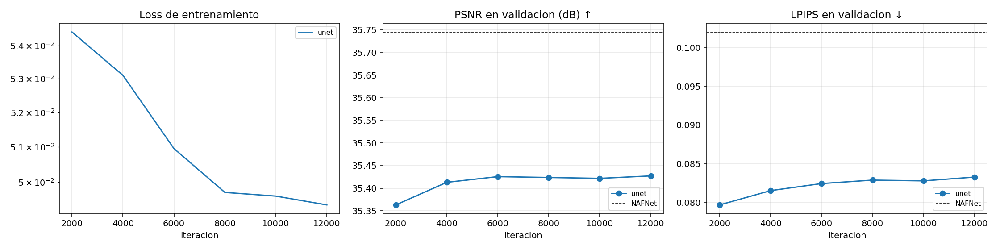

In [ ]:
import figures as fg
import pandas as pd
import os
import matplotlib.pyplot as plt
from IPython.display import Image, display

FIG = f"{DRIVE_DIR}/figuras"; os.makedirs(FIG, exist_ok=True)
runs = {r: f"{DRIVE_DIR}/difusion/{r}" for r in DIFF_RUNS if os.path.isfile(f"{DRIVE_DIR}/difusion/{r}/log.csv")}

if runs:
    fig, ax = plt.subplots(1, 3, figsize=(16, 4))
    for name, d in runs.items():
        p = os.path.join(d, "log.csv")
        df = pd.read_csv(p)
        # Limpiar columnas de espacios y pasarlas a minúsculas para evitar KeyErrors
        df.columns = df.columns.str.strip().str.lower()

        col_iter = 'iter' if 'iter' in df.columns else df.columns[0]
        col_loss = 'loss' if 'loss' in df.columns else df.columns[1]
        col_psnr = 'val_psnr' if 'val_psnr' in df.columns else None
        col_lpips = 'val_lpips' if 'val_lpips' in df.columns else None

        ax[0].plot(df[col_iter], df[col_loss], label=name)
        if col_psnr:
            ax[1].plot(df[col_iter], df[col_psnr], "o-", label=name)
        if col_lpips:
            ax[2].plot(df[col_iter], df[col_lpips], "o-", label=name)

        if "val_psnr_pred" in df.columns:
            ax[1].axhline(df["val_psnr_pred"].iloc[0], ls="--", c="k", lw=.8, label="NAFNet")
            ax[2].axhline(df["val_lpips_pred"].iloc[0], ls="--", c="k", lw=.8, label="NAFNet")

    ax[0].set(title="Loss de entrenamiento", xlabel="iteracion", yscale="log")
    ax[1].set(title="PSNR en validacion (dB) ↑", xlabel="iteracion")
    ax[2].set(title="LPIPS en validacion ↓", xlabel="iteracion")
    for a in ax:
        a.grid(alpha=.3)
        a.legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(f"{FIG}/curvas_difusion.png", dpi=140)
    plt.close()
    display(Image(f"{FIG}/curvas_difusion.png"))

## Etapa 3 - Evaluación
**Ablaciones** (100 imágenes de test repartidas entre todas las secuencias): punto de partida t₀, número de pasos y
promedio de N muestras, más las variantes `naf` y `solo` si existen. Úsenlas para elegir `SAMPLE_STEPS` y `SAMPLE_T0`
(idealmente con validación; aquí se reporta en test para el informe). Luego, la **tabla final** con las 1111 imágenes;
en ella se guardan en Drive **todas** las imágenes restauradas por la difusión principal (`eval/final/salidas/dif_unet/`).
Ambas se retoman donde quedaron.

In [ ]:
# Predicciones de test de la NAFNet (se restauran desde Drive si ya existen)
!cd {SRC} && python predict.py --root "{DATA_ROOT}" --split_json {SPLIT} --weights "{PRED_W}" --tag {PRED_TAG} --preds_dir {PREDS} --metrics_dir "{DRIVE_DIR}/nafnet" --parts test --need_preds {SH}

B = f"{DRIVE_DIR}/difusion"
def best(r):
    p = f"{B}/{r}/best.pt"
    return p if os.path.isfile(p) else None

methods = []
if best("unet"):
    u = best("unet")
    methods += [f"unet_t0_{t}={u}:20:{t}:1" for t in (0.25, 0.5, 0.75, 1.0)]
    methods += [f"unet_pasos_{s}={u}:{s}:0.5:1" for s in (5, 10)]
    methods += [f"unet_N_{n}={u}:20:0.5:{n}" for n in (2, 4)]
if best("naf"):
    methods.append(f"naf={best('naf')}:20:0.5:1")
if best("solo"):
    methods.append(f"solo={best('solo')}:20:1.0:1")
print(len(methods), "configuraciones de difusión")
METHODS_ARG = " ".join(f'"{m}"' for m in methods)
!cd {SRC} && python evaluate.py --root "{DATA_ROOT}" --split_json {SPLIT} --preds_dir {PREDS} --out_dir "{DRIVE_DIR}/eval/ablaciones" --n {ABLATION_N} --methods {METHODS_ARG}
display(Markdown(open(f"{DRIVE_DIR}/eval/ablaciones/summary.md").read()))

[oficial/test] restaurados 12 paquetes de predicciones desde Drive
[oficial/test] 1111 imagenes, faltan 0
8 configuraciones de difusión
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth
100% 233M/233M [00:01<00:00, 129MB/s]
evaluacion: 100% 30/30 [01:09<00:00,  2.30s/it]

| Metodo | n | PS

| Metodo | n | PSNR (dB) | SSIM | LPIPS | s/imagen |
|---|---|---|---|---|---|
| blur | 30 | 25.69 ± 3.94 | 0.7756 | 0.2818 | 0.00 |
| nafnet | 30 | 33.96 ± 2.51 | 0.9509 | 0.0754 | 0.00 |
| unet_t0_0.25 | 30 | 33.81 ± 2.45 | 0.9475 | 0.0668 | 13.53 |
| unet_t0_0.5 | 30 | 33.63 ± 2.39 | 0.9454 | 0.0620 | 13.98 |
| unet_t0_0.75 | 30 | 33.23 ± 2.27 | 0.9412 | 0.0568 | 13.99 |
| unet_t0_1.0 | 30 | 32.45 ± 2.15 | 0.9324 | 0.0571 | 13.71 |
| unet_pasos_5 | 30 | 33.72 ± 2.42 | 0.9477 | 0.0669 | 3.41 |
| unet_pasos_10 | 30 | 33.66 ± 2.40 | 0.9464 | 0.0637 | 6.79 |
| unet_N_2 | 30 | 33.78 ± 2.44 | 0.9479 | 0.0676 | 27.25 |
| unet_N_4 | 30 | 33.87 ± 2.47 | 0.9494 | 0.0715 | 55.17 |


In [ ]:
# Tabla final (1111 imágenes con FINAL_N = 0).
# Todas las salidas de la difusión principal (dif_unet) quedan en Drive: eval/final/salidas/dif_unet/<secuencia>/ (~1,4 GB)
final = []
if best("unet"):
    final.append(f"dif_unet={best('unet')}:{SAMPLE_STEPS}:{SAMPLE_T0}:1")
    #final.append(f"dif_unet_N4={best('unet')}:{SAMPLE_STEPS}:{SAMPLE_T0}:4")
if best("naf"):
    final.append(f"dif_naf={best('naf')}:{SAMPLE_STEPS}:{SAMPLE_T0}:1")
if best("solo"):
    final.append(f"dif_solo={best('solo')}:{SAMPLE_STEPS}:1.0:1")
FINAL_ARG = " ".join(f'"{m}"' for m in final)
!cd {SRC} && python evaluate.py --root "{DATA_ROOT}" --split_json {SPLIT} --preds_dir {PREDS} --out_dir "{DRIVE_DIR}/eval/final" --n {FINAL_N} --methods {FINAL_ARG} --save_all dif_unet
display(Markdown(open(f"{DRIVE_DIR}/eval/final/summary.md").read()))

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
evaluacion: 100% 1111/1111 [2:28:23<00:00,  8.01s/it]

| Metodo | n | PSNR (dB) | SSIM | LPIPS | s/imagen |
|---|---|---|---|---|---|
| blur | 1111 | 25.64 ± 3.34 | 0.7795 | 0.2910 | 0.00 |
| nafnet | 1111 | 33.71 ± 2.43 | 0.9475 | 0.0781 | 0.00 |
| dif_unet | 1111 | 33.43 ± 2.32 | 0.9430 | 0.0661 | 6.36 |


| Metodo | n | PSNR (dB) | SSIM | LPIPS | s/imagen |
|---|---|---|---|---|---|
| blur | 1111 | 25.64 ± 3.34 | 0.7795 | 0.2910 | 0.00 |
| nafnet | 1111 | 33.71 ± 2.43 | 0.9475 | 0.0781 | 0.00 |
| dif_unet | 1111 | 33.43 ± 2.32 | 0.9430 | 0.0661 | 6.36 |


## Etapa 4 - Resultados cualitativos y gráficos

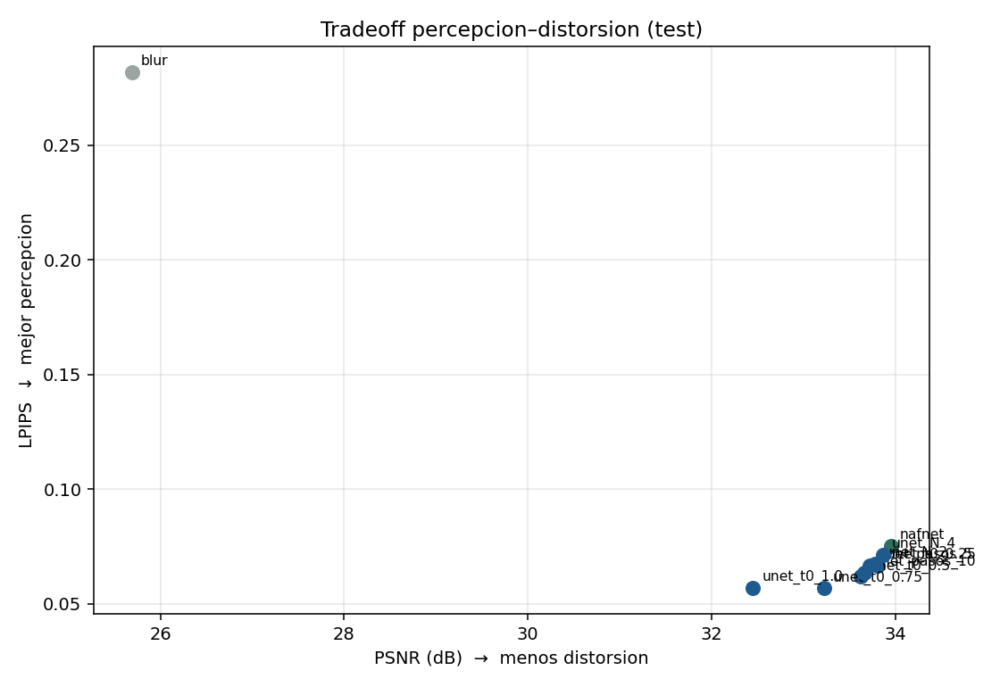

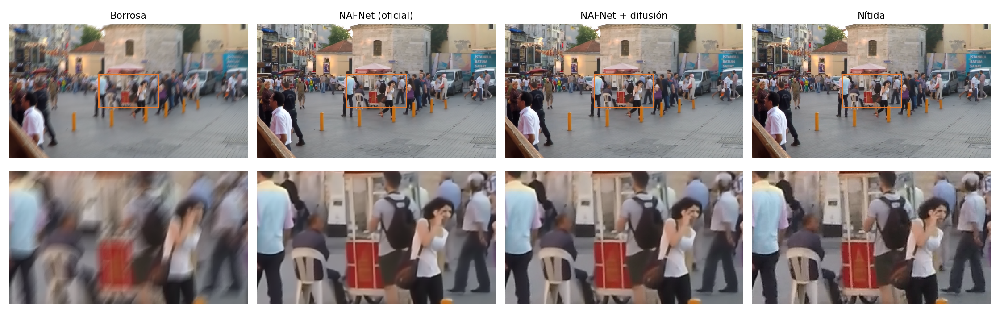

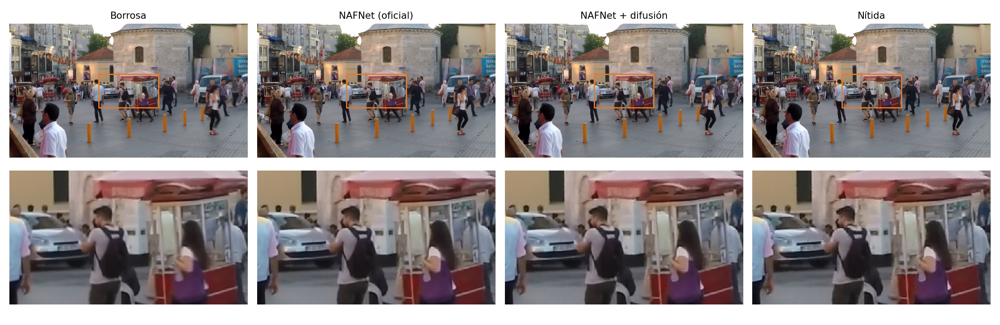

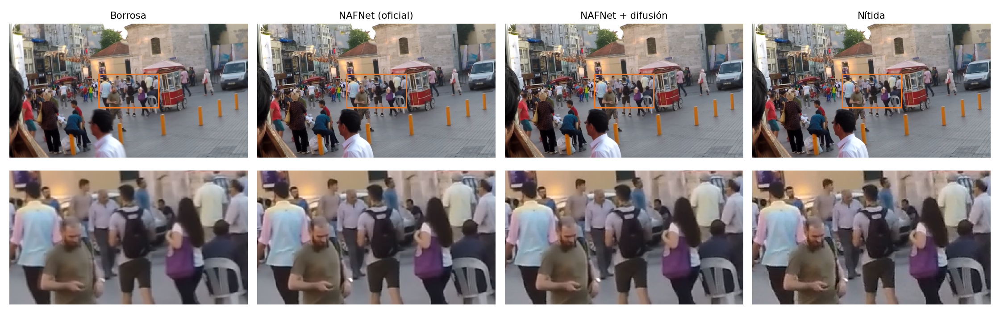

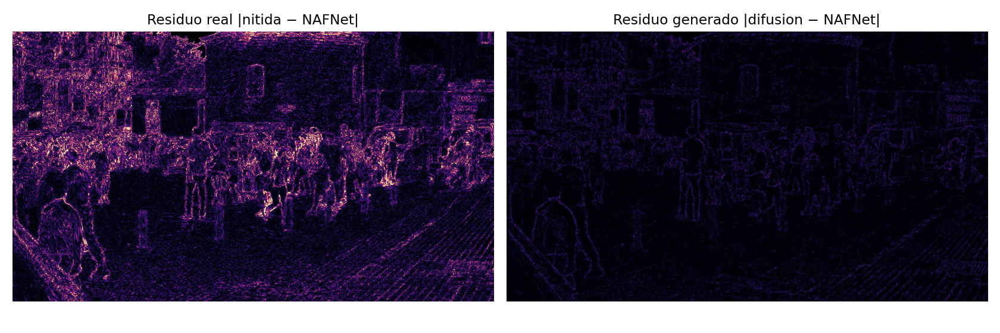

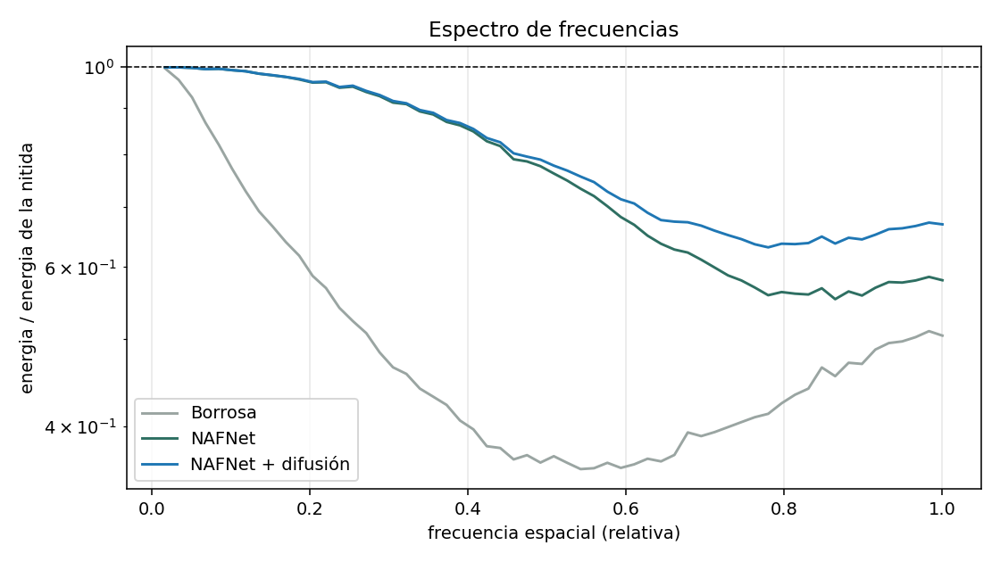

In [ ]:
EV = f"{DRIVE_DIR}/eval/ablaciones"
df = fg.perception_distortion([EV], f"{FIG}/percepcion_distorsion.png")
display(Image(f"{FIG}/percepcion_distorsion.png"))

main = "unet_t0_0.5"
idxs = sorted({int(os.path.basename(q)[:4]) for q in glob.glob(f"{EV}/images/*_sharp.png")})[:3]
for i in idxs:
    fg.comparison_grid(EV, i, ["blur", "nafnet", main, "sharp"], ["Borrosa", f"NAFNet ({PRED_TAG})", "NAFNet + difusión", "Nítida"],
                       f"{FIG}/comparacion_{i}.png")
    display(Image(f"{FIG}/comparacion_{i}.png"))
fg.residual_maps(EV, idxs[0], main, f"{FIG}/residuo_0.png")
display(Image(f"{FIG}/residuo_0.png"))
fg.spectrum_plot(EV, ["blur", "nafnet", main], ["Borrosa", "NAFNet", "NAFNet + difusión"], f"{FIG}/espectro.png")
display(Image(f"{FIG}/espectro.png"))

In [ ]:
# Incertidumbre (8 muestras) y animación del muestreo sobre una imagen de test
from common import read_u8, split_items, evenly, pred_path
from diffusion_lib import load_diffusion
diff, _ = load_diffusion(best("unet"), "cuda")
it = evenly(split_items(DATA_ROOT, SPLIT, "test"), ABLATION_N)[0]
b, p = read_u8(it["blur"]), read_u8(pred_path(PREDS, "test", it))
u = fg.uncertainty_map(diff, b, p, f"{FIG}/incertidumbre.png", n=8, steps=SAMPLE_STEPS, t0=SAMPLE_T0)
print(f"Desviación media entre muestras: {u:.2f} niveles")
display(Image(f"{FIG}/incertidumbre.png"))
fg.sampling_gif(diff, b, p, f"{FIG}/muestreo.gif", steps=SAMPLE_STEPS, t0=SAMPLE_T0)
display(Image(f"{FIG}/muestreo.gif"))
print("Todas las figuras quedaron en", FIG)

Output hidden; open in https://colab.research.google.com to view.

                  psnr   lpips
method                        
nafnet         33.9585  0.0754
unet_N_4       33.8660  0.0715
unet_t0_0.25   33.8079  0.0668
unet_N_2       33.7831  0.0676
unet_pasos_5   33.7215  0.0669
unet_pasos_10  33.6635  0.0637
unet_t0_0.5    33.6285  0.0620
unet_t0_0.75   33.2256  0.0568
unet_t0_1.0    32.4532  0.0571


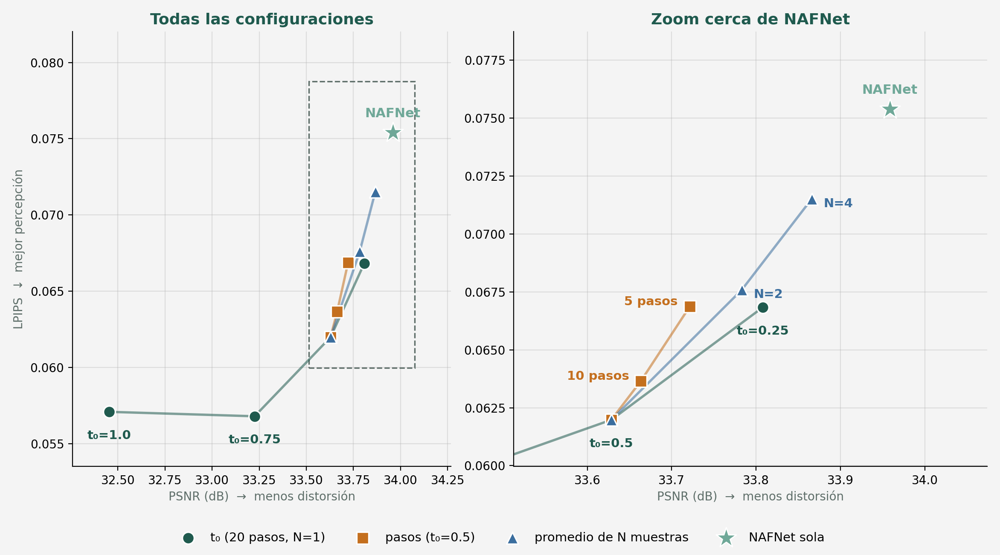

In [ ]:
import os, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display

FIG = f"{DRIVE_DIR}/figuras"; os.makedirs(FIG, exist_ok=True)
EV = f"{DRIVE_DIR}/eval/ablaciones"
df = pd.read_csv(f"{EV}/summary.csv").set_index("method")
df = df[df.index != "blur"]
print(df[["psnr", "lpips"]].sort_values("psnr", ascending=False).round(4))

bg, dark, mid, orange, blue, grey = "#f4f4f4", "#1f5a4e", "#6fa898", "#c46f1e", "#3b6e9e", "#5e6e69"
pt = lambda m: (df.loc[m, "psnr"], df.loc[m, "lpips"]) if m in df.index else None
SERIES = [  # (métodos, etiquetas, color, marcador, nombre, desplazamiento, alineación)
    (["unet_t0_0.25", "unet_t0_0.5", "unet_t0_0.75", "unet_t0_1.0"], ["t₀=0.25", "t₀=0.5", "t₀=0.75", "t₀=1.0"],
     dark, "o", "t₀ (20 pasos, N=1)", (0, -20), "center"),
    (["unet_pasos_5", "unet_pasos_10", "unet_t0_0.5"], ["5 pasos", "10 pasos", ""],
     orange, "s", "pasos (t₀=0.5)", (-10, 4), "right"),
    (["unet_t0_0.5", "unet_N_2", "unet_N_4"], ["", "N=2", "N=4"],
     blue, "^", "promedio de N muestras", (10, -4), "left"),
]

def draw(ax, labels, title):
    ax.set_facecolor(bg)
    for ms, labs, c, mk, name, off, ha in SERIES:
        xs = [(pt(m), l) for m, l in zip(ms, labs) if pt(m)]
        if not xs:
            continue
        ax.plot([p[0] for p, _ in xs], [p[1] for p, _ in xs], "-", color=c, lw=2, alpha=.55, zorder=2)
        ax.scatter([p[0] for p, _ in xs], [p[1] for p, _ in xs], s=100, color=c, marker=mk,
                   edgecolor="white", linewidth=1.2, zorder=4, label=name)
        for p, l in xs:
            if l and (labels or l in ("t₀=0.75", "t₀=1.0")):
                ax.annotate(l, p, xytext=off, textcoords="offset points", fontsize=10.5, color=c,
                            fontweight="bold", ha=ha, va="center")
    for m, c, mk, lab in [("naf", "#8c6bb1", "D", "variante naf"), ("solo", "#999999", "X", "solo difusión")]:
        if pt(m):
            ax.scatter(*pt(m), s=100, color=c, marker=mk, edgecolor="white", zorder=4, label=lab)
    if pt("nafnet"):
        ax.scatter(*pt("nafnet"), s=320, color=mid, marker="*", edgecolor="white", zorder=5, label="NAFNet sola")
        ax.annotate("NAFNet", pt("nafnet"), xytext=(0, 13), textcoords="offset points", ha="center",
                    fontsize=11, color=mid, fontweight="bold")
    ax.set_title(title, color=dark, fontweight="bold", fontsize=13)
    ax.set_xlabel("PSNR (dB)  →  menos distorsión", color=grey)
    ax.grid(alpha=.35); ax.set_axisbelow(True)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.72, 6.51), dpi=200, facecolor=bg,
                             gridspec_kw={"width_ratios": [1, 1.25]})
draw(a1, False, "Todas las configuraciones")
a1.set_ylabel("LPIPS  ↓  mejor percepción", color=grey)
a1.margins(x=0.12, y=0.15)
near = [m for m in df.index if m not in ("unet_t0_0.75", "unet_t0_1.0")]   # zoom cerca de NAFNet
draw(a2, True, "Zoom cerca de NAFNet")
x, y = df.loc[near, "psnr"], df.loc[near, "lpips"]
dx, dy = (x.max() - x.min()) or 0.1, (y.max() - y.min()) or 0.005
a2.set_xlim(x.min() - 0.35 * dx, x.max() + 0.35 * dx)
a2.set_ylim(y.min() - 0.15 * dy, y.max() + 0.25 * dy)
a1.add_patch(plt.Rectangle((a2.get_xlim()[0], a2.get_ylim()[0]), a2.get_xlim()[1] - a2.get_xlim()[0],
                           a2.get_ylim()[1] - a2.get_ylim()[0], fill=False, ec=grey, ls="--", lw=1.2))
h, l = a2.get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=len(l), frameon=False, fontsize=10.5)
plt.tight_layout(rect=[0, 0.07, 1, 1])
out = f"{FIG}/percepcion_distorsion_zoom.png"
plt.savefig(out, facecolor=bg)
plt.close()
display(Image(out))

Imagen: GOPR0385_11_01 003069.png
           lpips     psnr    ssim
method                           
blur      0.2873  28.7268  0.8747
nafnet    0.1242  37.3154  0.9601
dif_unet  0.0907  36.9921  0.9550
20 imágenes en /content/drive/MyDrive/IA2_Deblurring/figuras/slides
Zip: /content/drive/MyDrive/IA2_Deblurring/figuras/imagenes_slides.zip
σ medio entre muestras: 0.78 niveles


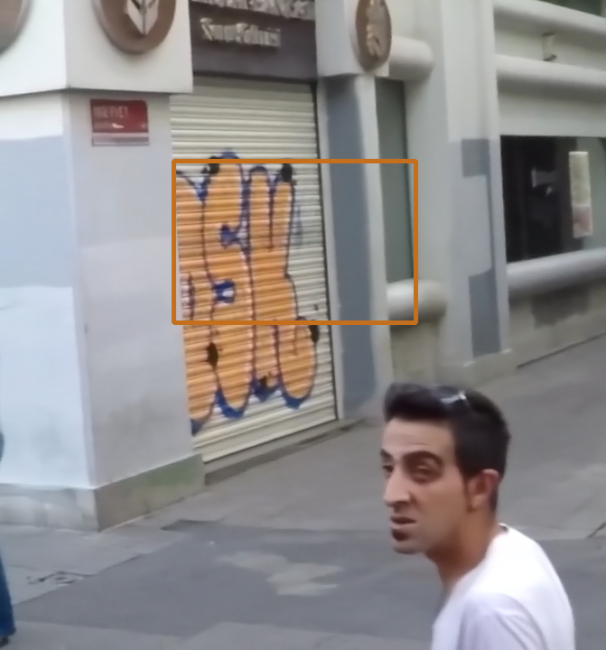

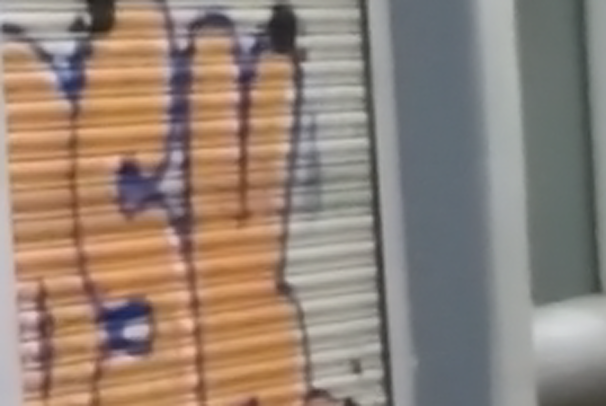

In [ ]:
# Imagenes para las slides 18 y 19
import os, shutil, cv2, numpy as np, pandas as pd, torch, matplotlib.cm as cm
from IPython.display import Image, display
from common import read_u8, write_u8, split_items, pred_path, u8_to_t, t_to_u8
from diffusion_lib import load_diffusion

ELEGIR = None          # None = automático; o ("GOPR0384_11_00", "000001.png") para fijar una imagen
OUT = f"{DRIVE_DIR}/figuras/slides"; os.makedirs(OUT, exist_ok=True)
FIN = f"{DRIVE_DIR}/eval/final"

# 1) imagen donde la difusión más mejora el LPIPS frente a NAFNet (sin perder más de 0.5 dB)
d = pd.read_csv(f"{FIN}/per_image.csv").pivot_table(index=["seq", "name"], columns="method", values=["psnr", "ssim", "lpips"])
gain = d["lpips"]["nafnet"] - d["lpips"]["dif_unet"]
ok = (d["psnr"]["nafnet"] - d["psnr"]["dif_unet"]) < 0.5
cand = gain[ok] if ok.any() else gain
seq, name = ELEGIR or cand.sort_values(ascending=False).index[0]
print("Imagen:", seq, name)
print(d.loc[(seq, name)].unstack(0).loc[["blur", "nafnet", "dif_unet"]].round(4))

it = next(i for i in split_items(DATA_ROOT, SPLIT, "test") if i["seq"] == seq and i["name"] == name)
blur, sharp = read_u8(it["blur"]), read_u8(it["sharp"])
naf = read_u8(pred_path(PREDS, "test", it))
dif = read_u8(f"{FIN}/salidas/dif_unet/{seq}/{name}")
H, W = sharp.shape[:2]

# 2) 8 muestras de la difusión (misma configuración que la tabla final) -> muestras e incertidumbre
dev = "cuda" if torch.cuda.is_available() else "cpu"
diff, _ = load_diffusion(best("unet"), dev)
g = torch.Generator(device=dev).manual_seed(0)
with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16, enabled=dev == "cuda"):
    _, stack = diff.sample(u8_to_t(blur, dev), u8_to_t(naf, dev), steps=SAMPLE_STEPS, t_start=SAMPLE_T0,
                           n_samples=8, tile=256, generator=g, return_samples=True)
m1, m2 = t_to_u8(stack[0:1]), t_to_u8(stack[1:2])
sigma = stack.float().std(0).mean(0).cpu().numpy() * 127.5

# 3) mapas en color (misma escala para residuo y error)
f32 = lambda a: a.astype(np.float32)
res = np.abs(f32(dif) - f32(naf)).mean(2)
err = np.abs(f32(dif) - f32(sharp)).mean(2)
vmax = np.percentile(np.abs(f32(sharp) - f32(naf)).mean(2), 99.5)
color = lambda a, v, cmap: (getattr(cm, cmap)(np.clip(a / max(v, 1e-6), 0, 1))[..., :3] * 255).astype(np.uint8)
res_c, err_c = color(res, vmax, "magma"), color(err, vmax, "magma")
sig_c = color(sigma, np.percentile(sigma, 99.5), "inferno")

# 4) zona del zoom: ventana con más residuo generado; recorte completo con la proporción de los marcos
zh = max(16, H // 4); zw = int(round(zh * 303 / 203))
box = cv2.boxFilter(res, -1, (zw, zh), normalize=True)
cy, cx = np.unravel_index(np.argmax(box), box.shape)
zy, zx = int(np.clip(cy - zh // 2, 0, H - zh)), int(np.clip(cx - zw // 2, 0, W - zw))
fw = min(W, int(round(H * 303 / 325)))
fx = int(np.clip(zx + zw // 2 - fw // 2, 0, W - fw))

def tiles(img, nombre):
    full = img[:, fx:fx + fw].copy()
    cv2.rectangle(full, (zx - fx, zy), (zx - fx + zw - 1, zy + zh - 1), (196, 111, 30), max(2, H // 200))
    write_u8(f"{OUT}/{nombre}_completa.png", cv2.resize(full, (606, 650), interpolation=cv2.INTER_AREA))
    write_u8(f"{OUT}/{nombre}_zoom.png", cv2.resize(img[zy:zy + zh, zx:zx + zw], (606, 406), interpolation=cv2.INTER_CUBIC))

for nombre, img in [("s18_1_borrosa", blur), ("s18_2_nafnet", naf), ("s18_3_residuo", res_c),
                    ("s18_4_difusion", dif), ("s18_5_nitida", sharp),
                    ("s19_1_nafnet", naf), ("s19_2_muestra1", m1), ("s19_3_muestra2", m2),
                    ("s19_4_sigma", sig_c), ("s19_5_error", err_c)]:
    tiles(img, nombre)
zip_path = shutil.make_archive(f"{DRIVE_DIR}/figuras/imagenes_slides", "zip", OUT)
print(f"{len(os.listdir(OUT))} imágenes en {OUT}\nZip: {zip_path}")
print(f"σ medio entre muestras: {sigma.mean():.2f} niveles")
display(Image(f"{OUT}/s18_4_difusion_completa.png", width=300), Image(f"{OUT}/s18_4_difusion_zoom.png", width=300))

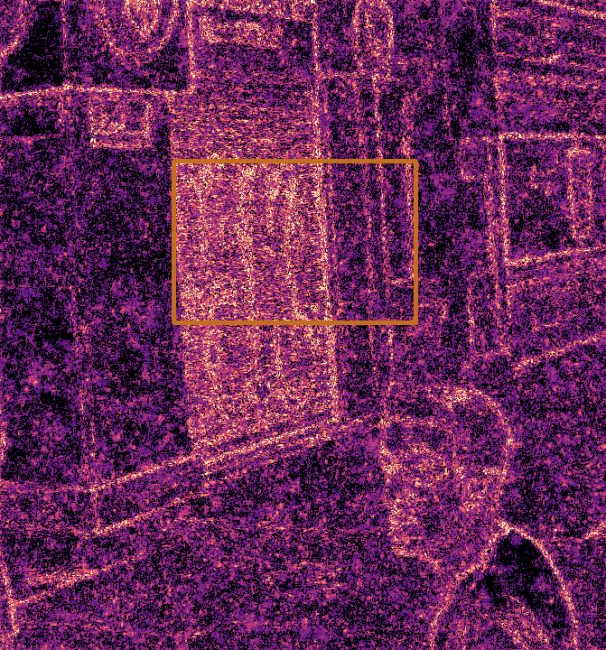

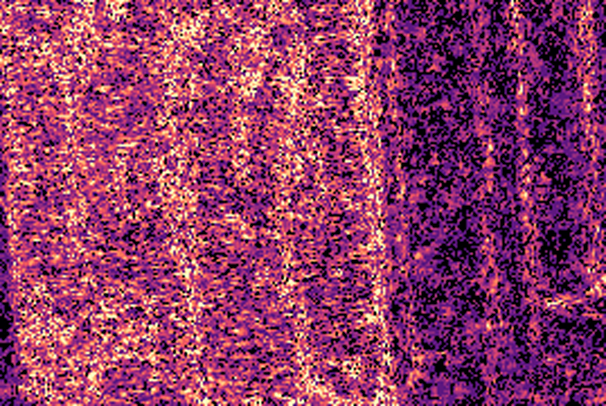

In [ ]:
# ===== Residuo más visible (solo regenera s18_3_residuo_*; no necesita GPU) =====
import os, cv2, numpy as np, pandas as pd, matplotlib.cm as cm
from IPython.display import Image, display
from common import read_u8, write_u8, split_items, pred_path

OUT, FIN = f"{DRIVE_DIR}/figuras/slides", f"{DRIVE_DIR}/eval/final"
f32 = lambda a: a.astype(np.float32)

if "res" not in globals():   # sesión nueva: recalcula la misma imagen y el mismo recorte
    d = pd.read_csv(f"{FIN}/per_image.csv").pivot_table(index=["seq", "name"], columns="method", values=["psnr", "lpips"])
    gain = d["lpips"]["nafnet"] - d["lpips"]["dif_unet"]
    ok = (d["psnr"]["nafnet"] - d["psnr"]["dif_unet"]) < 0.5
    seq, name = (gain[ok] if ok.any() else gain).sort_values(ascending=False).index[0]
    it = next(i for i in split_items(DATA_ROOT, SPLIT, "test") if i["seq"] == seq and i["name"] == name)
    naf = read_u8(pred_path(PREDS, "test", it))
    dif = read_u8(f"{FIN}/salidas/dif_unet/{seq}/{name}")
    H, W = naf.shape[:2]
    res = np.abs(f32(dif) - f32(naf)).mean(2)
    zh = max(16, H // 4); zw = int(round(zh * 303 / 203))
    cy, cx = np.unravel_index(np.argmax(cv2.boxFilter(res, -1, (zw, zh), normalize=True)), res.shape)
    zy, zx = int(np.clip(cy - zh // 2, 0, H - zh)), int(np.clip(cx - zw // 2, 0, W - zw))
    fw = min(W, int(round(H * 303 / 325)))
    fx = int(np.clip(zx + zw // 2 - fw // 2, 0, W - fw))
    print("Imagen:", seq, name)

# escala propia del residuo + raíz cuadrada: realza los detalles finos sin saturar los bordes
v = np.sqrt(np.clip(res / np.percentile(res, 99.5), 0, 1))
res_c = (cm.magma(v)[..., :3] * 255).astype(np.uint8)

full = res_c[:, fx:fx + fw].copy()
cv2.rectangle(full, (zx - fx, zy), (zx - fx + zw - 1, zy + zh - 1), (196, 111, 30), max(2, H // 200))
write_u8(f"{OUT}/s18_3_residuo_completa.png", cv2.resize(full, (606, 650), interpolation=cv2.INTER_AREA))
write_u8(f"{OUT}/s18_3_residuo_zoom.png",
         cv2.resize(res_c[zy:zy + zh, zx:zx + zw], (606, 406), interpolation=cv2.INTER_CUBIC))
display(Image(f"{OUT}/s18_3_residuo_completa.png", width=280), Image(f"{OUT}/s18_3_residuo_zoom.png", width=280))